# EO-Assisted On-Farm-Experiment (OFE) Calendar Reconstruction — Kenya Maize

## What this notebook does

This pipeline **cross-checks and gap-fills the crop-calendar dates** (sowing, topdressing,
harvest) recorded in an on-farm-experiment (OFE) maize database for Kenya, using independent
satellite evidence. It does **not** predict or impute yield — the two recorded yield columns
(grain and stover, kg/ha) are used only as a diagnostic cross-check against the satellite
canopy signal, to flag likely failed or stressed crops.

**Method, in short:**
1. Load the farmer-reported field-season records and the field polygons (NUTCAT), and keep
   only farmers with a near-complete seasonal record.
2. For each field-season, extract a cloud-masked Sentinel-2 optical time series (GCVI/NDVI/NDRE)
   and a speckle-filtered Sentinel-1 radar time series (VH/VH-VV cross-ratio) over the field
   polygon via Google Earth Engine, within a season-specific observation window.
3. Smooth each series (Savitzky-Golay) and detect phenological stages (start of season, peak,
   end of season) independently from the optical and radar curves.
4. Back-calculate sowing and topdressing dates from the satellite start-of-season using lags
   calibrated against the subset of records that do have a trustworthy recorded date, and
   validate those calibrations with leave-one-out and a temporal holdout (train on 2021-2023,
   test on 2024).
5. Build a dual-sensor agreement table, report accuracy (MAE, RMSE, R²) against the recorded
   dates where available, and compare against an independent phenology detector (TIMESAT-style
   Jönsson-Eklundh) as an external benchmark.
6. A reviewer-response section adds a naive seasonal-calendar baseline, a leave-one-farmer-out
   transfer test, and bootstrap prediction intervals.

**Inputs expected (not included in this repository):** a farmer-level Excel/CSV database of
planting/topdress/harvest dates and yields, and a shapefile/KMZ of field polygons. Paths are
set once in the configuration cell near the top. A Google Earth Engine project (your own) is
required for the extraction steps — set `GEE_PROJECT` to your project id.

**Privacy note:** this version has been prepared for public release. Farmer names have been
replaced throughout with anonymized codes (`Farmer_A` ... `Farmer_H`); no personally
identifying information, and no cloud credentials, are included.

**Key references for the methods adopted:**
- Franch, B. et al. (2022). Global crop calendars of maize and wheat in the framework of the
  WorldCereal project. *GIScience & Remote Sensing*, 59(1), 885-913.
  https://doi.org/10.1080/15481603.2022.2079273
- Jönsson, P. & Eklundh, L. (2004). TIMESAT — a program for analyzing time-series of satellite
  sensor data. *Computers & Geosciences*, 30(8), 833-845.
  https://doi.org/10.1016/j.cageo.2004.05.006
- Baetens, L., Desjardins, C. & Hagolle, O. (2019). Validation of Copernicus Sentinel-2 cloud
  masks obtained from MAJA, Sen2Cor, and FMask processors. *Remote Sensing*, 11(4), 433.
  https://doi.org/10.3390/rs11040433


In [1]:
!pip install -q earthengine-api geemap geopandas shapely pyogrio scipy xarray netCDF4

import ee, geemap
GEE_PROJECT = "your-gee-project-id"   # <-- set this
try:
    ee.Initialize(project=GEE_PROJECT)
except Exception:
    ee.Authenticate(); ee.Initialize(project=GEE_PROJECT)
print("Earth Engine:", ee.String("ready").getInfo())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 30.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 17.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 29.7 MB/s eta 0:00:00


*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


Earth Engine: ready


In [2]:
import os, glob, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import mapping

# version-agnostic trapezoid (numpy 2.x renamed trapz)
_trapz = np.trapezoid if hasattr(np, "trapezoid") else np.trapz

# --- Inputs ---
DB_PATH   = "/content/Kenya_file_2026.xlsx"  # csv or xlsx
DB_SHEET  = 0                      # 0 = first sheet; the country column is filtered below
COUNTRY   = "Kenya"
POLY_PATH = "/content/Polygon_farms_multi.shp"   # KMZ or .shp; KMZ keeps the separate polygons
OUT_DIR   = "/content/eo_ofe_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

# --- Column names (match your header) ---
COL = dict(country="country", farmer="farmer_name", field="field_number", season="season",
           treatment="treatment", harvest_area="harvest_area_m2",
           lat="latitude_dd", lon="longitude_dd",
           yield_kgha="grain_yield_kg_ha", stover_kgha="dry_weight_stover_kg_ha",
           plant="seeding_date", plant_alt="planting_date", basal="basal_fert_date",
           harvest="harvest_date", topdress="topdress1_date")

# --- Crop-failure / yield cross-check thresholds (yields are kg/ha, NOT t/ha) ---
GDD_BASE_C      = 10.0   # maize base temperature for growing degree-days
FAIL_YIELD_KGHA = 1000   # grain yield below this is treated as a likely failed/poor crop
WEAK_PEAK_GCVI  = 1.5    # peak GCVI below this suggests a weak canopy (possible failure)

# --- Treatment filter: keep only farmer practice (FP), drop on-farm treatment (OT) ---
KEEP_FP_ONLY = True      # OT yields run higher from fertilizer; excluded to avoid bias

# --- Point-to-polygon rescue tolerances (metres; computed in a LOCAL UTM zone) ---
FARMER_MATCH_TOL_M  = 200
DISTANCE_ONLY_TOL_M = 50
HARD_REJECT_M       = 500

# --- Extraction parameters ---
BUFFER_M      = 10       # fallback buffer where a field has no polygon
S2_CLOUD_PROB = 30
S1_ORBIT      = "ALL"    # ALL keeps both passes; per-orbit offsets are harmonised downstream
WINDOW_PAD_D  = 10       # pad on the per-season extraction / search window
DEKAD_STEP_D  = 5        # resampling grid step (days)
POLY_REDUCER  = "mean"   # "mean" or "median" reduction over the field polygon

# --- Optical phenology (Sentinel-2 GCVI) ---
SAVGOL_WIN    = 5        # Savitzky-Golay window (25-day span on the 5-day grid)
SOS_FRAC      = 0.25     # start-of-season amplitude fraction
MIN_S2_OBS    = 5        # drop field-seasons with fewer clear S2 dates

# --- Sentinel-1 phenometrics (VH/VV cross-ratio) ---
SG_WIN_S1     = 5        # Savitzky-Golay window
SG_POLY_S1    = 3        # polynomial order
MIN_S1_OBS    = 7        # min S1 dates for phenometric extraction
SORS_FRAC     = 0.30     # radar start-of-season amplitude fraction (skip soil-moisture noise)
S1_MIN_AMP    = 0.04     # min cross-ratio amplitude to trust a radar start-of-season
S1_ORBIT_NORMALIZE = True # remove per-relative-orbit level offsets before smoothing
SAT_AGREE_DAYS = 21      # wider: absorbs the structural (radar) vs greenness (optical) offset

# --- Which sensor leads each stage. "optical" = S2 primary with S1 as fallback; "radar" = the
# reverse. Earlier versions were radar-led for the start of season on the assumption that radar is
# the cloud-proof workhorse. On this dataset that assumption does not hold: the S1 cross-ratio
# start-of-season scatters against recorded sowing with an IQR roughly twice the optical one, and
# switching to optical-led roughly halves the seeding error and cuts the topdress error by two
# thirds. Section 7b prints the head-to-head so the choice stays evidence-based, not assumed.
SENSOR_LEAD_START = "optical"   # "optical" or "radar"
SENSOR_LEAD_PEAK  = "optical"   # peak has no ground truth here; kept consistent with the sensor
                                # that demonstrably works on these fields

# --- Seeding back-calculation (calibrated, not assumed) ---
MIN_CALIB_N   = 8        # min recorded sowings needed to calibrate the SOS->sowing lag
FALLBACK_LAG  = (22, 16, 28)  # (median, p25, p75) days used only if the calibration set is small
SLOPE_SCREEN_DEG = 15    # flag field-seasons steeper than this (SAR terrain caution)

# --- Optional manual season-window overrides ---
SEASON_WINDOWS = {}      # {season: (start, end)}

# --- Panel completeness filter (applied early, before any extraction) ---
MIN_SEASONS_PER_FARMER = 5      # keep farmers present in at least this many seasons
                                # (7 seasons exist; 6 of 7 is strict and costs whole farmers)
FILTER_REQUIRES_DATES  = False  # False: count a season by presence; True: require sowing AND harvest

# --- TAMSAT daily rainfall (local NetCDF covariate, matched to each season window) ---
TAMSAT_PATH       = "/content/TAMSAT_daily_Kenya.nc"
TAMSAT_RAINDAY_MM = 1.0         # daily threshold (mm) for counting a rain day

# --- Implausible-calendar screen: NULL the offending date, never delete the row ---
CYCLE_MIN_D, CYCLE_MAX_D = 90, 160   # plausible maize sowing-to-harvest span (days)

# --- Harvest: optical-led + calibrated senescence-to-harvest lag ---
HARV_LAG_MIN_D, HARV_LAG_MAX_D = -30, 60   # plausible EOS-to-harvest lag for calibration
MIN_HARV_CALIB_N = 8
FALLBACK_HARV_LAG = 5.0              # days, used only if the calibration set is too small

# --- Second, agronomic harvest route: sowing estimate + crop cycle length ---
# The maize cycle is thermally determined and tight (sd about 9 d here), whereas the interval from
# canopy senescence to the farmer actually harvesting is a human decision and loose (sd about 14 d).
# Once the sowing estimate is good this route is the more accurate one, but it uses NO independent
# satellite information about harvest: it is the sowing estimate plus a constant. Both routes are
# reported; which one to publish depends on whether the claim is EO detection or date gap-filling.
CYCLE_CALIB_MIN_D, CYCLE_CALIB_MAX_D = 90, 180
MIN_CYCLE_CALIB_N = 8
FALLBACK_CYCLE_D = 130.0

# --- Topdress timing model: predicted from the satellite start-of-season ---
TOPDRESS_MIN_D, TOPDRESS_MAX_D = 7, 90   # plausible topdress window after sowing (screen)
TD_LAG_MIN_D, TD_LAG_MAX_D = -30, 90     # plausible SOS-to-topdress lag for calibration
MIN_TD_CALIB_N = 8
FALLBACK_TD_LAG = 17.0               # days after SOS
RAIN_SNAP = False                    # True: snap the predicted topdress to a TAMSAT rain day
RAIN_SNAP_WINDOW_D = 7               # search +/- this many days
TOPDRESS_RAIN_MM = 5.0               # daily rain that makes an application likely


In [3]:
def load_db(path, sheet):
    if path.lower().endswith(('.xlsx', '.xls')):
        xls = pd.ExcelFile(path)
        if sheet in (None, 0) or sheet not in xls.sheet_names:
            if sheet not in (None, 0):
                print(f"Sheet '{sheet}' not found. Available: {xls.sheet_names}. Using first.")
            sheet = xls.sheet_names[0]
        return pd.read_excel(xls, sheet_name=sheet)
    return pd.read_csv(path)

raw = load_db(DB_PATH, DB_SHEET)
print("Loaded", len(raw), "rows,", raw.shape[1], "columns")
df = raw[raw[COL["country"]].astype(str).str.strip().str.lower() == COUNTRY.lower()].copy()
print(COUNTRY, "rows:", len(df))

# Keep only farmer-practice (FP) plots; drop on-farm treatment (OT) to avoid fertilizer bias
if KEEP_FP_ONLY and COL["treatment"] in df.columns:
    tr = df[COL["treatment"]].astype(str).str.strip().str.upper()
    fp_mask = tr.str.startswith("FP") | tr.str.contains("FARMER")
    print("Treatment counts:", df[COL["treatment"]].value_counts().to_dict())
    df = df[fp_mask].copy()
    print("Kept FP rows:", len(df))
elif KEEP_FP_ONLY:
    print("WARNING: treatment column not found; FP filter skipped")

if COL["harvest_area"] in df.columns:
    ha = pd.to_numeric(df[COL["harvest_area"]], errors="coerce")
    print(f"Harvest area m2: median {ha.median():.1f}, range {ha.min():.1f}-{ha.max():.1f} "
          f"(Sentinel-2 pixel = 100 m2; EO signal is the field, yield is a scaled quadrat)")

def find_col(frame, candidates):
    """Match a column name ignoring case, surrounding whitespace, and a leading BOM."""
    norm = {str(c).strip().lstrip("\ufeff").lower(): c for c in frame.columns}
    for cand in candidates:
        if cand is None:
            continue
        k = str(cand).strip().lower()
        if k in norm:
            return norm[k]
    return None

def _col(frame, *cands):
    hit = find_col(frame, list(cands))
    return frame[hit] if hit is not None else pd.Series(pd.NaT, index=frame.index)

# planting: keep the seeding/planting coalesce, but match names case/space-insensitively
_p1 = find_col(df, [COL["plant"], "seeding_date", "sowing_date", "date_planted", "planting"])
_p2 = find_col(df, [COL.get("plant_alt"), "planting_date"])
if _p1 is not None and _p2 is not None:
    df["_plant"] = df[_p1].fillna(df[_p2])
elif _p1 is not None:
    df["_plant"] = df[_p1]
elif _p2 is not None:
    df["_plant"] = df[_p2]
else:
    df["_plant"] = pd.Series(pd.NaT, index=df.index)
df["_harvest"]  = _col(df, COL["harvest"], "harvesting_date", "date_harvest")
df["_topdress"] = _col(df, COL["topdress"])
df["_basal"]    = _col(df, COL["basal"])
print(f"Date columns matched -> planting: {_p1 or _p2} | "
      f"harvest: {find_col(df, [COL['harvest'], 'harvesting_date', 'date_harvest'])}")
for c in ["_plant", "_harvest", "_topdress", "_basal"]:
    df[c] = pd.to_datetime(df[c], errors="coerce")

# Implausible-calendar screen. A wrong harvest date does not invalidate the sowing date or the
# satellite curve, so the offending DATE is nulled and the ROW is kept. Deleting rows here also
# deletes field-seasons with no recorded harvest at all (a NaN fails any range test), which are
# exactly the rows this pipeline exists to gap-fill, and it silently drops farmers below the
# season-completeness bar downstream.
df["maize_cycle_days"] = (df["_harvest"] - df["_plant"]).dt.days
_bad = df["maize_cycle_days"].notna() & (
    (df["maize_cycle_days"] < CYCLE_MIN_D) | (df["maize_cycle_days"] > CYCLE_MAX_D))
_nmiss = int(df["_harvest"].isna().sum())
df.loc[_bad, "_harvest"] = pd.NaT          # null the date, keep the row
df.loc[_bad, "maize_cycle_days"] = np.nan
print(f"Calendar screen ({CYCLE_MIN_D}-{CYCLE_MAX_D} d): nulled {int(_bad.sum())} implausible harvest "
      f"dates; kept all {len(df)} rows")
print(f"  harvest already missing (left as-is for gap-filling): {_nmiss}")
# Same treatment for topdressing: a topdress date before sowing, or months after it, is a
# data-entry error rather than a real operation. Nulling it here (instead of only excluding it from
# the calibration, as earlier versions did) keeps the reported topdress error consistent with the
# model: otherwise impossible records stay in the error table and inflate the MAE while the
# leave-one-out figure, computed on screened records only, looks far better. Same rule, one place.
_td = (df["_topdress"] - df["_plant"]).dt.days
_tdbad = _td.notna() & ((_td < TOPDRESS_MIN_D) | (_td > TOPDRESS_MAX_D))
df.loc[_tdbad, "_topdress"] = pd.NaT
print(f"Topdress screen ({TOPDRESS_MIN_D}-{TOPDRESS_MAX_D} d after sowing): nulled {int(_tdbad.sum())} "
      f"implausible topdress dates; kept all {len(df)} rows")

_ok = df["maize_cycle_days"].dropna()
if len(_ok):
    print(f"  retained cycle length (d): p05 {_ok.quantile(.05):.0f} | median {_ok.median():.0f} | "
          f"p95 {_ok.quantile(.95):.0f}")

df["_grain"]  = pd.to_numeric(df[COL["yield_kgha"]], errors="coerce")
df["_stover"] = pd.to_numeric(df[COL["stover_kgha"]], errors="coerce") if COL["stover_kgha"] in df.columns else np.nan
gmax = df["_grain"].max()
if pd.notna(gmax) and gmax < 50:
    print(f"WARNING: max grain yield is {gmax:.1f}; values look like t/ha, not kg/ha. Check units.")
else:
    print(f"Grain yield kg/ha: median {df['_grain'].median():.0f}, max {gmax:.0f} (expected hundreds to ~10,000)")

lat, lon = df[COL["lat"]], df[COL["lon"]]
KENYA_BBOX = (-5.0, 5.5, 33.5, 42.0)
good = (lat.notna() & lon.notna() & (lat != 0) & (lon != 0)
        & lat.between(KENYA_BBOX[0], KENYA_BBOX[1]) & lon.between(KENYA_BBOX[2], KENYA_BBOX[3]))
print("Dropping", int((~good).sum()), "rows with bad coordinates")
df = df[good].copy()

df["fs_id"] = (df[COL["farmer"]].astype(str).str.strip() + "__"
               + df[COL["field"]].astype(str).str.strip() + "__"
               + df[COL["season"]].astype(str).str.strip())

Loaded 3338 rows, 131 columns
Kenya rows: 3338
Treatment counts: {'OT': 1680, 'FP': 1658}
Kept FP rows: 1658
Harvest area m2: median 4.5, range 0.0-12.0 (Sentinel-2 pixel = 100 m2; EO signal is the field, yield is a scaled quadrat)
Date columns matched -> planting: seeding_date | harvest: harvest_date
Calendar screen (90-160 d): nulled 46 implausible harvest dates; kept all 1658 rows
  harvest already missing (left as-is for gap-filling): 252
Topdress screen (7-90 d after sowing): nulled 52 implausible topdress dates; kept all 1658 rows
  retained cycle length (d): p05 117 | median 130 | p95 143
Grain yield kg/ha: median 2545, max 9253 (expected hundreds to ~10,000)
Dropping 108 rows with bad coordinates


In [4]:
agg = {"_grain": "mean", "_stover": "mean", COL["lat"]: "mean", COL["lon"]: "mean",
       COL["farmer"]: "first", COL["field"]: "first", COL["season"]: "first",
       "_plant": "min", "_harvest": "max", "_topdress": "min", "_basal": "min"}
if COL["harvest_area"] in df.columns:
    df["_ha_m2"] = pd.to_numeric(df[COL["harvest_area"]], errors="coerce"); agg["_ha_m2"] = "mean"
fs = df.groupby("fs_id").agg(agg).reset_index().rename(columns={
    "_grain": "grain_kgha", "_stover": "stover_kgha", COL["lat"]: "lat", COL["lon"]: "lon",
    COL["farmer"]: "farmer", COL["field"]: "field", COL["season"]: "season"})
print("Field-seasons:", len(fs), "| farmers:", fs.farmer.nunique(), "| seasons:", fs.season.nunique())
print("Grain yield present:", int(fs.grain_kgha.notna().sum()),
      "| stover present:", int(fs.stover_kgha.notna().sum()))
fs.head()

Field-seasons: 63 | farmers: 14 | seasons: 7
Grain yield present: 56 | stover present: 29


,fs_id,grain_kgha,stover_kgha,lat,lon,farmer,field,season,_plant,_harvest,_topdress,_basal,_ha_m2
0,Farmer_A__11__LR2023,3182.472862,6583.985912,-0.543646,37.498264,Farmer_A,11,LR2023,2023-03-14,2023-07-24,2023-05-05,2023-03-14,4.5
1,Farmer_A__11__LR2024,2108.870370,NaN,-0.543707,37.498264,Farmer_A,11,LR2024,2024-03-28,2024-08-14,2024-04-28,2024-03-28,4.5
2,Farmer_A__11__SR2022,NaN,NaN,-0.543668,37.498419,Farmer_A,11,SR2022,2022-10-26,NaT,2022-11-18,2022-10-26,NaN
3,Farmer_A__11__SR2023,3786.445210,NaN,-0.543670,37.497968,Farmer_A,11,SR2023,2023-10-19,2024-02-19,2023-11-23,2023-10-19,4.5
4,Farmer_A__11__SR2024,2033.713992,NaN,-0.543707,37.498264,Farmer_A,11,SR2024,2024-10-26,2025-03-06,2024-11-29,2024-10-26,4.5


In [5]:
# Retain only farmers present in at least MIN_SEASONS_PER_FARMER seasons.
if FILTER_REQUIRES_DATES:
    _ok = fs["_plant"].notna() & fs["_harvest"].notna()
else:
    _ok = pd.Series(True, index=fs.index)

_seasons_per_farmer = fs[_ok].groupby("farmer")["season"].nunique()
_keep = _seasons_per_farmer[_seasons_per_farmer >= MIN_SEASONS_PER_FARMER].index

_before, _bf = len(fs), fs["farmer"].nunique()
fs = fs[fs["farmer"].isin(_keep)].reset_index(drop=True)
print(f"Season filter: kept {fs['farmer'].nunique()} of {_bf} farmers with >= "
      f"{MIN_SEASONS_PER_FARMER} {'date-complete ' if FILTER_REQUIRES_DATES else ''}seasons")
print(f"Field-seasons: {_before} -> {len(fs)} (dropped {_before - len(fs)})")
print("Seasons per kept farmer:",
      _seasons_per_farmer.loc[_keep].sort_values(ascending=False).to_dict())

Season filter: kept 8 of 14 farmers with >= 5 seasons
Field-seasons: 63 -> 50 (dropped 13)
Seasons per kept farmer: {'Farmer_F': 7, 'Farmer_E': 7, 'Farmer_B': 6, 'Farmer_C': 6, "Farmer_G": 6, 'Farmer_H': 6, 'Farmer_D': 5, 'Farmer_A': 5}


In [6]:
import shapely

def load_polygons(path):
    parts = []
    if path.lower().endswith(".kmz"):
        exdir = "/content/_kmz_extract"; os.makedirs(exdir, exist_ok=True)
        with zipfile.ZipFile(path) as z:
            z.extractall(exdir)
        kmls = glob.glob(os.path.join(exdir, "**", "*.kml"), recursive=True)
        if not kmls:
            raise FileNotFoundError("No .kml found inside the KMZ")
        src = kmls[0]
        try:
            import pyogrio
            layers = [l[0] for l in pyogrio.list_layers(src)]
        except Exception:
            layers = [None]
        for ln in (layers or [None]):
            try:
                parts.append(gpd.read_file(src, layer=ln) if ln else gpd.read_file(src))
            except Exception as e:
                print("layer skipped:", e)
    else:
        parts.append(gpd.read_file(path))   # shapefile (needs .shx/.dbf/.prj alongside)
    gdf = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True))
    gdf = gdf[gdf.geometry.notna()].copy()
    gdf["geometry"] = shapely.force_2d(gdf.geometry.values)        # drop Z (== R's st_zm)
    gdf = gdf[gdf.geometry.geom_type.isin(["Polygon", "MultiPolygon"])]
    gdf = gdf.explode(index_parts=False).reset_index(drop=True)    # split multipart -> separate fields
    gdf["geometry"] = gdf.geometry.buffer(0)                       # make valid
    gdf = gdf[gdf.geometry.area > 0]
    if gdf.crs is None:
        gdf = gdf.set_crs(4326)
    return gdf.to_crs(4326).reset_index(drop=True)

polys = load_polygons(POLY_PATH)
name_col = next((c for c in ["Name", "name", "Field", "id", "ID"] if c in polys.columns), None)
polys["polygon_id"] = polys[name_col].astype(str) if name_col else ["poly_" + str(i) for i in range(len(polys))]
# make ids unique across exploded multipart parts
dup = polys.groupby("polygon_id").cumcount()
polys["polygon_id"] = np.where(dup > 0, polys["polygon_id"] + "_p" + dup.astype(str), polys["polygon_id"])
print("Polygons read:", len(polys), "| CRS:", polys.crs.to_epsg(), "| has Z:", bool(polys.geometry.has_z.any()))
print("Polygon ids:", list(polys["polygon_id"])[:30])

Polygons read: 27 | CRS: 4326 | has Z: False
Polygon ids: ['All_NUTCAT', 'All_NUTCAT_p1', 'All_NUTCAT_p2', 'All_NUTCAT_p3', 'All_NUTCAT_p4', 'All_NUTCAT_p5', 'All_NUTCAT_p6', 'All_NUTCAT_p7', 'All_NUTCAT_p8', 'All_NUTCAT_p9', 'All_NUTCAT_p10', 'All_NUTCAT_p11', 'All_NUTCAT_p12', 'All_NUTCAT_p13', 'All_NUTCAT_p14', 'All_NUTCAT_p15', 'All_NUTCAT_p16', 'All_NUTCAT_p17', 'All_NUTCAT_p18', 'All_NUTCAT_p19', 'All_NUTCAT_p20', 'All_NUTCAT_p21', 'All_NUTCAT_p22', 'All_NUTCAT_p23', 'All_NUTCAT_p24', 'All_NUTCAT_p25', 'All_NUTCAT_p26']


/tmp/ipykernel_919/2514520087.py:31: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf = gdf[gdf.geometry.area > 0]


In [7]:
# Spatial join, then rescue outside points by nearest polygon + farmer match.
# Distances are metric in a LOCAL UTM zone (picked from the data centroid), not Web Mercator.
pts = gpd.GeoDataFrame(fs.copy(), geometry=gpd.points_from_xy(fs.lon, fs.lat), crs=4326)
joined = gpd.sjoin(pts, polys[["geometry"]], predicate="within", how="left")
joined = joined[~joined.index.duplicated(keep="first")].reset_index(drop=True)
inside_idx = joined["index_right"].values

mean_lon = float(pts.geometry.x.mean()); mean_lat = float(pts.geometry.y.mean())
utm_zone = int((mean_lon + 180) // 6) + 1
EPSG_UTM = (32600 if mean_lat >= 0 else 32700) + utm_zone
print(f"Local metric CRS for distances: EPSG:{EPSG_UTM} (UTM zone {utm_zone}{'N' if mean_lat>=0 else 'S'})")

poly_farmers = {}
for pi, fa in zip(inside_idx, fs["farmer"].astype(str).str.strip().str.lower()):
    if pd.notna(pi):
        poly_farmers.setdefault(int(pi), set()).add(fa)

pm = polys.to_crs(EPSG_UTM); ptm = pts.to_crs(EPSG_UTM)
poly_for_fs = {}; assignment = {}
for i, row in fs.reset_index(drop=True).iterrows():
    pi = inside_idx[i]
    if pd.notna(pi):
        poly_for_fs[row.fs_id] = polys.geometry.iloc[int(pi)]; assignment[row.fs_id] = "inside"; continue
    d = pm.distance(ptm.geometry.iloc[i]); nn = int(d.idxmin()); nd = float(d.min())
    fa = str(row.farmer).strip().lower()
    if nd > HARD_REJECT_M:
        assignment[row.fs_id] = "still_outside"
    elif fa in poly_farmers.get(nn, set()) and nd <= FARMER_MATCH_TOL_M:
        poly_for_fs[row.fs_id] = polys.geometry.iloc[nn]; assignment[row.fs_id] = "rescued_farmer"
    elif nd <= DISTANCE_ONLY_TOL_M:
        poly_for_fs[row.fs_id] = polys.geometry.iloc[nn]; assignment[row.fs_id] = "rescued_distance"
    else:
        assignment[row.fs_id] = "still_outside"

fs["assignment"] = fs.fs_id.map(assignment)
print("Assignment outcomes:", pd.Series(assignment).value_counts().to_dict())
print(f"FP field-seasons matched: {len(poly_for_fs)} of {len(fs)} "
      f"({100*len(poly_for_fs)/max(len(fs),1):.0f}%); rest use a {BUFFER_M} m buffer")

Local metric CRS for distances: EPSG:32737 (UTM zone 37S)
Assignment outcomes: {'inside': 42, 'rescued_farmer': 5, 'still_outside': 3}
FP field-seasons matched: 47 of 50 (94%); rest use a 10 m buffer


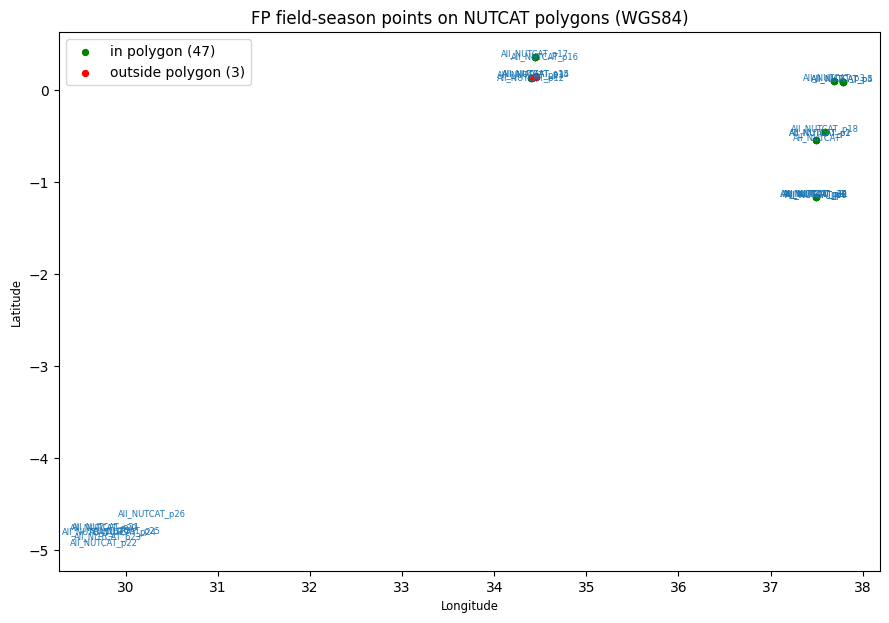

Points still outside any polygon:
                 fs_id      farmer season      lat       lon
Farmer_E__5__LR2024 Farmer_E LR2024 0.132326 34.405457
Farmer_E__5__SR2024 Farmer_E SR2024 0.132326 34.405457
Farmer_H__7__SR2023 Farmer_H SR2023 0.142597 34.456848


In [8]:
fig, ax = plt.subplots(figsize=(9, 9))
polys.boundary.plot(ax=ax, color="tab:blue", lw=1)
for _, r in polys.iterrows():
    c = r.geometry.representative_point()
    ax.annotate(str(r["polygon_id"]), (c.x, c.y), fontsize=6, color="tab:blue", ha="center")
matched = pts[pts.fs_id.isin(poly_for_fs)]
unmatched = pts[~pts.fs_id.isin(poly_for_fs)]
if len(matched):
    matched.plot(ax=ax, color="green", markersize=18, label=f"in polygon ({len(matched)})")
if len(unmatched):
    unmatched.plot(ax=ax, color="red", markersize=18, label=f"outside polygon ({len(unmatched)})")
minx, miny, maxx, maxy = polys.total_bounds
mx = (maxx - minx) * 0.05 or 0.001; my = (maxy - miny) * 0.05 or 0.001
ax.set_xlim(minx - mx, maxx + mx); ax.set_ylim(miny - my, maxy + my)
ax.set_aspect("equal", adjustable="box")
ax.legend(); ax.set_title("FP field-season points on NUTCAT polygons (WGS84)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/fig1_overlap_check.png", dpi=200); plt.show()

if len(unmatched):
    print("Points still outside any polygon:")
    print(unmatched[["fs_id", "farmer", "season", "lat", "lon"]].to_string(index=False))
else:
    print("All FP field-season points are assigned to a polygon.")

In [9]:
import shapely

def load_polygons(path):
    parts = []
    if path.lower().endswith(".kmz"):
        exdir = "/content/_kmz_extract"; os.makedirs(exdir, exist_ok=True)
        with zipfile.ZipFile(path) as z:
            z.extractall(exdir)
        kmls = glob.glob(os.path.join(exdir, "**", "*.kml"), recursive=True)
        if not kmls:
            raise FileNotFoundError("No .kml found inside the KMZ")
        src = kmls[0]
        try:
            import pyogrio
            layers = [l[0] for l in pyogrio.list_layers(src)]
        except Exception:
            layers = [None]
        for ln in (layers or [None]):
            try:
                parts.append(gpd.read_file(src, layer=ln) if ln else gpd.read_file(src))
            except Exception as e:
                print("layer skipped:", e)
    else:
        parts.append(gpd.read_file(path))   # shapefile (needs .shx/.dbf/.prj alongside)
    gdf = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True))
    gdf = gdf[gdf.geometry.notna()].copy()
    gdf["geometry"] = shapely.force_2d(gdf.geometry.values)        # drop Z (== R's st_zm)
    gdf = gdf[gdf.geometry.geom_type.isin(["Polygon", "MultiPolygon"])]
    gdf = gdf.explode(index_parts=False).reset_index(drop=True)    # split multipart -> separate fields
    gdf["geometry"] = gdf.geometry.buffer(0)                       # make valid
    gdf = gdf[gdf.geometry.area > 0]
    if gdf.crs is None:
        gdf = gdf.set_crs(4326)
    return gdf.to_crs(4326).reset_index(drop=True)

polys = load_polygons(POLY_PATH)
name_col = next((c for c in ["Name", "name", "Field", "id", "ID"] if c in polys.columns), None)
polys["polygon_id"] = polys[name_col].astype(str) if name_col else ["poly_" + str(i) for i in range(len(polys))]
# make ids unique across exploded multipart parts
dup = polys.groupby("polygon_id").cumcount()
polys["polygon_id"] = np.where(dup > 0, polys["polygon_id"] + "_p" + dup.astype(str), polys["polygon_id"])
print("Polygons read:", len(polys), "| CRS:", polys.crs.to_epsg(), "| has Z:", bool(polys.geometry.has_z.any()))
print("Polygon ids:", list(polys["polygon_id"])
[:30])

# Build one Earth Engine geometry per field-season: polygon if matched, else buffered point
def ee_geometry_for(fid, row):
    if fid in poly_for_fs:
        # Set geodesic=True for polygons to ensure correct geodesic calculations
        return ee.Geometry(mapping(poly_for_fs[fid]), proj="EPSG:4326", geodesic=True)
    # Removed geodesic=True from buffer as it's not a supported argument for ee.Geometry.Point().buffer()
    return ee.Geometry.Point([float(row.lon), float(row.lat)]).buffer(BUFFER_M)

geom_map = {r.fs_id: ee_geometry_for(r.fs_id, r) for _, r in fs.iterrows()}
print("EE geometries built:", len(geom_map))

Polygons read: 27 | CRS: 4326 | has Z: False
Polygon ids: ['All_NUTCAT', 'All_NUTCAT_p1', 'All_NUTCAT_p2', 'All_NUTCAT_p3', 'All_NUTCAT_p4', 'All_NUTCAT_p5', 'All_NUTCAT_p6', 'All_NUTCAT_p7', 'All_NUTCAT_p8', 'All_NUTCAT_p9', 'All_NUTCAT_p10', 'All_NUTCAT_p11', 'All_NUTCAT_p12', 'All_NUTCAT_p13', 'All_NUTCAT_p14', 'All_NUTCAT_p15', 'All_NUTCAT_p16', 'All_NUTCAT_p17', 'All_NUTCAT_p18', 'All_NUTCAT_p19', 'All_NUTCAT_p20', 'All_NUTCAT_p21', 'All_NUTCAT_p22', 'All_NUTCAT_p23', 'All_NUTCAT_p24', 'All_NUTCAT_p25', 'All_NUTCAT_p26']
EE geometries built: 50


/tmp/ipykernel_919/1029784827.py:31: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf = gdf[gdf.geometry.area > 0]


In [10]:
def derive_windows(frame, pad):
    out = {}
    for s, g in frame.groupby("season"):
        start, end = g["_plant"].min(), g["_harvest"].max()
        if pd.isna(start) or pd.isna(end):
            start = g["_plant"].min()
            end = (start + pd.Timedelta(days=180)) if pd.notna(start) else pd.NaT
        if pd.isna(start) or pd.isna(end):
            continue
        out[str(s)] = ((start - pd.Timedelta(days=pad)).strftime("%Y-%m-%d"),
                       (end + pd.Timedelta(days=pad)).strftime("%Y-%m-%d"))
    return out

windows = derive_windows(fs, WINDOW_PAD_D); windows.update(SEASON_WINDOWS)
for s, w in sorted(windows.items()):
    print(s, w)

LR 2022 ('2022-03-05', '2022-09-21')
LR2023 ('2023-03-04', '2023-08-17')
LR2024 ('2024-03-08', '2024-08-29')
SR2021 ('2021-09-11', '2022-03-21')
SR2022 ('2022-08-31', '2023-03-09')
SR2023 ('2023-09-13', '2024-03-10')
SR2024 ('2024-09-16', '2025-03-22')


In [11]:
def fs_features_for_season(season):
    g = fs[fs.season.astype(str) == str(season)]
    feats = [ee.Feature(geom_map[r.fs_id], {"fs_id": r.fs_id}) for _, r in g.iterrows()]
    return ee.FeatureCollection(feats)

def fc_to_df(fc, props):
    n = fc.size().getInfo()
    if n == 0:
        return pd.DataFrame(columns=props)
    info = fc.toList(n).getInfo()
    return pd.DataFrame([f["properties"] for f in info], columns=props)

In [12]:
import ee

# ---- Sentinel-2 (s2cloudless mask) ----
def s2_collection(geom_fc, start, end):
    # Determine the geometry to use for filtering bounds
    if isinstance(geom_fc, ee.FeatureCollection):
        geom_filter_bounds = geom_fc.geometry(maxError=1)
    else: # Assume it's an ee.Geometry object
        geom_filter_bounds = geom_fc
    s2 = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED").filterBounds(geom_filter_bounds).filterDate(start, end)
    cld = ee.ImageCollection("COPERNICUS/S2_CLOUD_PROBABILITY").filterBounds(geom_filter_bounds).filterDate(start, end)
    joined = ee.Join.saveFirst("cloud").apply(
        primary=s2, secondary=cld,
        condition=ee.Filter.equals(leftField="system:index", rightField="system:index"))
    def prep(img):
        img = ee.Image(img)
        prob = ee.Image(img.get("cloud")).select("probability")
        scl = img.select("SCL")
        is_cloud  = prob.gte(S2_CLOUD_PROB).Or(scl.eq(8)).Or(scl.eq(9)).Or(scl.eq(10))
        is_shadow = scl.eq(3).focal_max(300, "circle", "meters")   # dilate to catch penumbral shadow
        is_bad    = scl.eq(0).Or(scl.eq(1)).Or(scl.eq(11))          # no-data, saturated/defective, snow/ice
        clear = is_cloud.Not().And(is_shadow.Not()).And(is_bad.Not())
        img = img.updateMask(clear)
        ndvi = img.normalizedDifference(["B8", "B4"]).rename("NDVI")
        ndre = img.normalizedDifference(["B8", "B5"]).rename("NDRE")
        gcvi = img.select("B8").divide(img.select("B3")).subtract(1).rename("GCVI")
        return img.addBands([ndvi, ndre, gcvi])
    return ee.ImageCollection(joined).map(prep)

def extract_series(coll, points_fc, bands, scale=10, img_props=None):
    img_props = list(img_props or [])
    def per_image(img):
        img = ee.Image(img)
        d = img.date().format("YYYY-MM-dd")
        red = ee.Reducer.median() if POLY_REDUCER == "median" else ee.Reducer.mean()
        # Pass the FeatureCollection directly to reduceRegions to retain fs_id for each feature
        fc = img.select(bands).reduceRegions(points_fc, red, scale)
        def tag(f):
            f = f.set("date", d)
            for p in img_props:
                f = f.set(p, img.get(p))
            return f
        return fc.map(tag)
    return coll.map(per_image).flatten()

s2_rows = []
for s, (start, end) in windows.items():
    pts_s = fs_features_for_season(s)
    if pts_s.size().getInfo() == 0:
        continue
    coll = s2_collection(pts_s, start, end)
    d = fc_to_df(extract_series(coll, pts_s, ["NDVI", "NDRE", "GCVI"]),
                 ["fs_id", "date", "NDVI", "NDRE", "GCVI"])
    d["season"] = s; s2_rows.append(d)
    print(f"S2 {s}: {len(d)} reductions")

s2_df = pd.concat(s2_rows, ignore_index=True) if s2_rows else pd.DataFrame()
s2_df = s2_df.dropna(subset=["NDVI"]).copy()
s2_df["date"] = pd.to_datetime(s2_df["date"])

S2 LR 2022: 600 reductions
S2 LR2023: 896 reductions
S2 LR2024: 1251 reductions
S2 SR2021: 456 reductions
S2 SR2022: 1168 reductions
S2 SR2023: 1144 reductions
S2 SR2024: 1350 reductions


In [13]:
# ---- Optional Landsat 8 gap-filling of the Sentinel-2 GCVI/NDVI series ----
USE_LANDSAT      = False   # False reproduces the Sentinel-2-only pipeline exactly
LANDSAT_GAP_DAYS = 20      # insert an L8 scene only inside an S2 gap longer than this (days)
LANDSAT_MIN_SEP  = 7       # skip an L8 scene within this many days of an existing S2 scene

def l8_collection(geom, start, end):
    """Landsat 8 C2 L2 surface reflectance with GCVI and NDVI, cloud-masked and dilated."""
    def prep(img):
        qa = img.select("QA_PIXEL")
        bad = (qa.bitwiseAnd(1 << 0).neq(0)      # fill
               .Or(qa.bitwiseAnd(1 << 1).neq(0))  # dilated cloud
               .Or(qa.bitwiseAnd(1 << 2).neq(0))  # cirrus
               .Or(qa.bitwiseAnd(1 << 3).neq(0))  # cloud
               .Or(qa.bitwiseAnd(1 << 4).neq(0))) # cloud shadow
        bad = bad.focal_max(90, "circle", "meters")   # dilate the mask (Baetens et al. 2019)
        # C2 L2 scaling to surface reflectance: DN * 0.0000275 - 0.2
        sr = img.select(["SR_B3", "SR_B4", "SR_B5"]).multiply(0.0000275).add(-0.2)
        green, red, nir = sr.select("SR_B3"), sr.select("SR_B4"), sr.select("SR_B5")
        gcvi = nir.divide(green).subtract(1).rename("GCVI")
        ndvi = nir.subtract(red).divide(nir.add(red)).rename("NDVI")
        return img.addBands([gcvi, ndvi]).updateMask(bad.Not())
    return (ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
            .filterBounds(geom).filterDate(start, end)
            .filter(ee.Filter.lt("CLOUD_COVER", 80)).map(prep))

def merge_gapfill(s2, l8, gap_days, min_sep):
    """Keep every Sentinel-2 reduction; add a Landsat reduction only where it fills an S2 gap
    longer than gap_days and is not within min_sep days of an existing S2 scene."""
    if not len(l8):
        return s2
    add = []
    for fid, gl in l8.groupby("fs_id"):
        s2d = np.sort(pd.to_datetime(s2.loc[s2.fs_id == fid, "date"]).values.astype("datetime64[D]"))
        for _, r in gl.iterrows():
            t = np.datetime64(pd.Timestamp(r["date"]), "D")
            if len(s2d) == 0:
                add.append(r); continue
            nd = int(np.min(np.abs((s2d - t).astype("timedelta64[D]").astype(int))))
            if nd <= min_sep:
                continue                                  # redundant with an existing S2 scene
            before, after = s2d[s2d <= t], s2d[s2d >= t]
            if len(before) and len(after):
                interval = int((after[0] - before[-1]).astype("timedelta64[D]").astype(int))
                if interval > gap_days:
                    add.append(r)
            elif nd > gap_days:                           # beyond the S2 temporal span
                add.append(r)
    if not add:
        return s2
    out = pd.concat([s2, pd.DataFrame(add)], ignore_index=True)
    return out.sort_values(["fs_id", "date"]).reset_index(drop=True)

if USE_LANDSAT:
    if "sensor" not in s2_df.columns:
        s2_df["sensor"] = "S2"
    l8_rows = []
    for s, (start, end) in windows.items():
        pts_s = fs_features_for_season(s)
        if pts_s.size().getInfo() == 0:
            continue
        coll = l8_collection(pts_s.geometry(), start, end)
        d = fc_to_df(extract_series(coll, pts_s, ["GCVI", "NDVI"], scale=30),
                     ["fs_id", "date", "GCVI", "NDVI"])
        d["season"] = s; l8_rows.append(d)
        print(f"L8 {s}: {len(d)} reductions")
    l8_df = pd.concat(l8_rows, ignore_index=True) if l8_rows else pd.DataFrame()
    if len(l8_df):
        l8_df = l8_df.dropna(subset=["GCVI"]).copy()
        l8_df["date"] = pd.to_datetime(l8_df["date"]); l8_df["sensor"] = "L8"
        _n0 = len(s2_df)
        s2_df = merge_gapfill(s2_df, l8_df, LANDSAT_GAP_DAYS, LANDSAT_MIN_SEP)
        _added = len(s2_df) - _n0
        print(f"\nLandsat 8 gap-filling: {len(l8_df)} L8 reductions available, "
              f"{_added} inserted into S2 gaps > {LANDSAT_GAP_DAYS} d")
        print(f"  optical series: {_n0} -> {len(s2_df)} reductions "
              f"({100*_added/max(_n0,1):.0f}% added)")
        _wl8 = s2_df[s2_df.get('sensor','S2') == 'L8']['fs_id'].nunique() if 'sensor' in s2_df else 0
        print(f"  field-seasons receiving at least one L8 scene: {_wl8}")
    else:
        print("Landsat 8: no reductions returned for the requested windows.")
else:
    print("Landsat 8 gap-filling disabled (USE_LANDSAT=False); Sentinel-2-only series unchanged.")

Landsat 8 gap-filling disabled (USE_LANDSAT=False); Sentinel-2-only series unchanged.


In [14]:
import ee

# ---- Sentinel-1 (dB -> linear, focal speckle filter; both passes, orbit carried) ----
# Note: S1_GRD is not radiometrically terrain-flattened. The VH/VV cross-ratio largely cancels
# incidence-angle dependence, which is one reason it is preferred for phenology; steep fields
# are still flagged later (SLOPE_SCREEN_DEG). Per-orbit level offsets are harmonised at the
# phenometric step, so ASCENDING and DESCENDING passes can be pooled safely.
def s1_collection(geom_fc, start, end):
    # Determine the geometry to use for filtering bounds
    if isinstance(geom_fc, ee.FeatureCollection):
        geom_filter_bounds = geom_fc.geometry(maxError=1)
    else: # Assume it's an ee.Geometry object
        geom_filter_bounds = geom_fc
    s1 = (ee.ImageCollection("COPERNICUS/S1_GRD").filterBounds(geom_filter_bounds).filterDate(start, end)
          .filter(ee.Filter.eq("instrumentMode", "IW"))
          .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
          .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH")))
    if S1_ORBIT not in (None, "ALL", "BOTH"):
        s1 = s1.filter(ee.Filter.eq("orbitProperties_pass", S1_ORBIT))
    def prep(img):
        lin = ee.Image(10).pow(img.select(["VV", "VH"]).divide(10)).focal_mean(30, "circle", "meters")
        vv, vh = lin.select("VV"), lin.select("VH")
        ratio = vh.divide(vv).rename("VH_VV")
        rvi = vh.multiply(4).divide(vv.add(vh)).rename("RVI")
        vh_db = vh.log10().multiply(10).rename("VH")
        return img.addBands([vh_db, ratio, rvi], overwrite=True)
    return s1.map(prep)

s1_rows = []
for s, (start, end) in windows.items():
    pts_s = fs_features_for_season(s)
    if pts_s.size().getInfo() == 0:
        continue
    coll = s1_collection(pts_s, start, end)
    d = fc_to_df(extract_series(coll, pts_s, ["VH", "VH_VV", "RVI"],
                                img_props=["relativeOrbitNumber_start", "orbitProperties_pass"]),
                 ["fs_id", "date", "VH", "VH_VV", "RVI", "relativeOrbitNumber_start", "orbitProperties_pass"])
    d = d.rename(columns={"relativeOrbitNumber_start": "rel_orbit", "orbitProperties_pass": "orbit_pass"})
    d["season"] = s; s1_rows.append(d)
    print(f"S1 {s}: {len(d)} reductions")

s1_df = pd.concat(s1_rows, ignore_index=True) if s1_rows else pd.DataFrame()
s1_df = s1_df.dropna(subset=["VH"]).copy()
s1_df["date"] = pd.to_datetime(s1_df["date"])
if "rel_orbit" not in s1_df.columns:
    s1_df["rel_orbit"] = np.nan
print("S1 clean reductions:", len(s1_df),
      "| relative orbits:", s1_df["rel_orbit"].nunique() if len(s1_df) else 0)

S1 LR 2022: 465 reductions
S1 LR2023: 553 reductions
S1 LR2024: 702 reductions
S1 SR2021: 456 reductions
S1 SR2022: 736 reductions
S1 SR2023: 720 reductions
S1 SR2024: 837 reductions
S1 clean reductions: 1065 | relative orbits: 5


In [15]:
# ---- Ancillary covariates: one value per field-season ---- consider ********************TWI*
def extract_ancillary(points_fc, start, end):
    # Get the union geometry of the FeatureCollection with a maxError for geodesic operations
    geom_union = points_fc.geometry(maxError=1)
    chirps = ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY").filterDate(start, end).sum().rename("rain_mm")
    era = ee.ImageCollection("ECMWF/ERA5_LAND/DAILY_AGGR").filterDate(start, end)
    tmax = era.select("temperature_2m_max").mean().subtract(273.15).rename("tmax_c")
    sm = era.select("volumetric_soil_water_layer_1").mean().rename("soilm")
    def daily_gdd(img):
        tmean = img.select("temperature_2m_max").add(img.select("temperature_2m_min")).divide(2).subtract(273.15)
        return tmean.subtract(GDD_BASE_C).max(0).rename("gdd")
    gdd = era.map(daily_gdd).sum().rename("gdd")
    srtm = ee.Image("USGS/SRTMGL1_003").rename("elev_m")
    slope = ee.Terrain.slope(srtm).rename("slope_deg")
    # Filter ancillary data by the union geometry
    img = ee.Image.cat([chirps, tmax, sm, gdd, srtm, slope])
    # add iSDA soil pH only if the asset resolves (validated client-side)
    try:
        ee.data.getAsset("ISDASOIL/Africa/v1/ph")
        img = img.addBands(ee.Image("ISDASOIL/Africa/v1/ph").select("mean_0_20").rename("soil_ph"))
    except Exception:
        pass
    cols = ["fs_id", "rain_mm", "tmax_c", "soilm", "gdd", "elev_m", "slope_deg", "soil_ph"]
    # Pass the FeatureCollection directly to reduceRegions to retain fs_id for each feature
    return fc_to_df(img.reduceRegions(points_fc, ee.Reducer.mean(), 100), cols)

anc_rows = []
for s, (start, end) in windows.items():
    pts_s = fs_features_for_season(s)
    if pts_s.size().getInfo() == 0:
        continue
    anc_rows.append(extract_ancillary(pts_s, start, end))
anc_df = pd.concat(anc_rows, ignore_index=True) if anc_rows else pd.DataFrame()
print("Ancillary rows:", len(anc_df))

# Cache raw extractions (covariates are cached for downstream modelling; not used to date the calendar)
for name, d in [("s2_timeseries", s2_df), ("s1_timeseries", s1_df),
                ("ancillary", anc_df), ("field_seasons", fs)]:
    d.to_csv(f"{OUT_DIR}/{name}.csv", index=False)
print("Cached extractions to", OUT_DIR)

Ancillary rows: 50
Cached extractions to /content/eo_ofe_outputs


In [16]:
# ---- TAMSAT daily rainfall, matched to each field-season's season window ----
def _open_tamsat(path):
    import xarray as xr
    ds = xr.open_dataset(path)
    rain = next((v for v in ["rfe", "rfe_filled", "precip", "precipitation", "rain", "rainfall", "tamsat"]
                 if v in ds.data_vars), None)
    if rain is None:
        threeD = [v for v in ds.data_vars if ds[v].ndim == 3]
        rain = threeD[0] if threeD else list(ds.data_vars)[0]
    latn = next((c for c in ["lat", "latitude", "y", "Y"] if c in ds.coords), None)
    lonn = next((c for c in ["lon", "longitude", "x", "X"] if c in ds.coords), None)
    tn   = next((c for c in ["time", "t", "date"] if c in ds.coords), None)
    return ds, rain, latn, lonn, tn

def _tamsat_window(ds, rain, latn, lonn, tn, lat, lon, start, end):
    da = ds[rain].sel({tn: slice(start, end)})
    if da[tn].size == 0:
        return dict(tamsat_rain_mm=np.nan, tamsat_raindays=np.nan, tamsat_days=0)
    v = da.sel({latn: float(lat), lonn: float(lon)}, method="nearest").values.astype("float64").ravel()
    v = v[np.isfinite(v)]
    if v.size == 0:
        return dict(tamsat_rain_mm=np.nan, tamsat_raindays=np.nan, tamsat_days=0)
    return dict(tamsat_rain_mm=float(v.sum()),
                tamsat_raindays=int((v >= TAMSAT_RAINDAY_MM).sum()),
                tamsat_days=int(v.size))

if os.path.exists(TAMSAT_PATH):
    ds_t, RAIN, LATN, LONN, TN = _open_tamsat(TAMSAT_PATH)
    tmin = str(np.datetime_as_string(ds_t[TN].values.min(), unit="D"))
    tmax = str(np.datetime_as_string(ds_t[TN].values.max(), unit="D"))
    print(f"TAMSAT: variable '{RAIN}', coords ({LATN}, {LONN}, {TN}), coverage {tmin} to {tmax}")
    rows = []
    for _, r in fs.iterrows():
        w = windows.get(str(r.season))
        rec = (_tamsat_window(ds_t, RAIN, LATN, LONN, TN, r.lat, r.lon, w[0], w[1])
               if w else dict(tamsat_rain_mm=np.nan, tamsat_raindays=np.nan, tamsat_days=0))
        rec["fs_id"] = r.fs_id
        rows.append(rec)
    tamsat_df = pd.DataFrame(rows)[["fs_id", "tamsat_rain_mm", "tamsat_raindays", "tamsat_days"]]
    ds_t.close()
    n_out = int((tamsat_df["tamsat_days"] == 0).sum())
    print(f"TAMSAT matched {len(tamsat_df)} field-seasons; {n_out} had no TAMSAT day inside their "
          f"season window (window outside file coverage or point off-grid)")
    print(f"Seasonal rainfall (mm): median {tamsat_df['tamsat_rain_mm'].median():.0f}, "
          f"range {tamsat_df['tamsat_rain_mm'].min():.0f}-{tamsat_df['tamsat_rain_mm'].max():.0f}")
    anc_df = anc_df.merge(tamsat_df, on="fs_id", how="left") if len(anc_df) else tamsat_df
    anc_df.to_csv(f"{OUT_DIR}/ancillary.csv", index=False)   # refresh cache with TAMSAT columns
else:
    print(f"TAMSAT file not found at {TAMSAT_PATH}; skipping. Set TAMSAT_PATH to add it.")
    for c in ["tamsat_rain_mm", "tamsat_raindays", "tamsat_days"]:
        if len(anc_df) and c not in anc_df.columns:
            anc_df[c] = np.nan

TAMSAT: variable 'sm_c4grass', coords (lat, lon, time), coverage 2015-01-01 to 2026-11-16
TAMSAT matched 50 field-seasons; 0 had no TAMSAT day inside their season window (window outside file coverage or point off-grid)
Seasonal rainfall (mm): median 3020, range 5-14330


In [17]:
from IPython.display import Image as IPyImage, display

example_fs = s2_df.fs_id.value_counts().index[3]   # a well-observed field-season
ex_row = fs[fs.fs_id == example_fs].iloc[0]
ex_geom = geom_map[example_fs]
ex_win = windows[str(ex_row.season)]
print("Example field-season:", example_fs)

s2_med = s2_collection(ex_geom, *ex_win).median()
rgb_url = s2_med.visualize(bands=["B4", "B3", "B2"], min=0, max=3000).getThumbURL(
    {"region": ex_geom, "dimensions": 320})
ndvi_url = s2_med.select("NDVI").visualize(
    min=0, max=0.9, palette=["white", "yellow", "green"]).getThumbURL(
    {"region": ex_geom, "dimensions": 320})
print("Sentinel-2 true colour (left) and NDVI (right):")
display(IPyImage(url=rgb_url), IPyImage(url=ndvi_url))

vh_med = s1_collection(ex_geom, *ex_win).select("VH").mean()
vh_url = vh_med.visualize(min=-20, max=-5, palette=["black", "gray", "white"]).getThumbURL(
    {"region": ex_geom, "dimensions": 320})
print("Sentinel-1 VH backscatter (dB):")
display(IPyImage(url=vh_url))

Example field-season: Farmer_D__9__SR2024
Sentinel-2 true colour (left) and NDVI (right):


Sentinel-1 VH backscatter (dB):


In [18]:
from scipy.signal import savgol_filter

def _resample_smooth(dates, values, ws, we, sg_win, sg_poly, min_obs):
    """Interp to a regular grid, SG-smooth, and return an observed-span mask so detection
    never keys on flat-extrapolated (unobserved) tails."""
    s = pd.Series(pd.to_numeric(pd.Series(values), errors="coerce").values,
                  index=pd.to_datetime(pd.Series(dates).values)).dropna().sort_index()
    s = s[~s.index.duplicated()]
    s = s[(s.index >= pd.Timestamp(ws)) & (s.index <= pd.Timestamp(we))]
    n = len(s)
    if n < min_obs:
        return None, None, None, n
    grid = pd.date_range(ws, we, freq=f"{DEKAD_STEP_D}D")
    xi = np.interp(grid.asi8, s.index.asi8, s.values)
    w = min(sg_win, len(xi) - (1 - len(xi) % 2))
    if w >= sg_poly + 2 and w % 2 == 1:
        xi = savgol_filter(xi, w, sg_poly)
    obs = (grid >= s.index.min()) & (grid <= s.index.max())
    return grid, xi, obs, n

def _obs_slice(grid, x, obs):
    idx = np.where(obs)[0]
    if len(idx) < 3:
        return None, None
    lo, hi = idx[0], idx[-1]
    return grid[lo:hi + 1], x[lo:hi + 1]

def _threshold_up(g, x, frac):
    """Green-up crossing measured from the bare-soil TROUGH that precedes the peak, not from the
    first value in the window.

    A field-season whose series starts high (residual green from the previous crop, volunteers, or
    weeds ahead of land preparation) already sits above base + frac*amplitude at its first
    observation. Taking the first crossing then returns the window edge, so the start of season
    lands weeks BEFORE the crop was sown, which is physically impossible. Anchoring on the trough
    is the standard phenological definition: green-up is measured from the seasonal minimum
    preceding the peak.

    base and amp are still returned on the FULL observed span so the end-of-season / harvest path
    downstream is unchanged. For a series that starts at bare soil the trough is the first sample
    and this reduces exactly to the previous behaviour.
    """
    base, amp = float(np.nanmin(x)), float(np.nanmax(x) - np.nanmin(x))
    pk = int(np.argmax(x))
    if amp <= 0:
        return pd.NaT, pk, base, amp
    tr = int(np.argmin(x[:pk + 1])) if pk > 0 else 0    # seasonal trough before the peak
    seg = x[tr:pk + 1]
    sbase = float(np.nanmin(seg))
    samp = float(x[pk] - sbase)
    if samp <= 0:
        return pd.NaT, pk, base, amp
    up = np.where(seg >= sbase + frac * samp)[0]
    return (g[tr + up[0]] if len(up) else pd.NaT), pk, base, amp

def _threshold_up_confirmed(g, x, frac, min_amp):
    """Threshold up-crossing on the rising limb, confirmed by a sustained positive slope,
    to suppress noise blips on bare soil before the true canopy rise."""
    base, amp = float(np.nanmin(x)), float(np.nanmax(x) - np.nanmin(x))
    pk = int(np.argmax(x))
    if amp <= min_amp:
        return pd.NaT, pk, base, amp
    tr = int(np.argmin(x[:pk + 1])) if pk > 0 else 0    # anchor on the trough, as for optical
    target = float(np.nanmin(x[tr:pk + 1])) + frac * float(x[pk] - np.nanmin(x[tr:pk + 1]))
    dx = np.gradient(x)
    cand = np.where((x[:pk + 1] >= target) & (dx[:pk + 1] > 0))[0]
    cand = cand[cand >= tr]
    if len(cand) == 0:
        return pd.NaT, pk, base, amp
    for c in cand:
        if c + 2 < len(x) and np.all(dx[c:c + 2] > 0):
            return g[c], pk, base, amp
    return g[cand[0]], pk, base, amp

# ---- optical (Sentinel-2 GCVI) ----
def optical_stages(g2, ws, we):
    out = {"n_s2": 0}
    if not len(g2):
        return out
    grid, gcvi, obs, n = _resample_smooth(g2["date"], g2["GCVI"], ws, we, SAVGOL_WIN, 2, MIN_S2_OBS)
    out["n_s2"] = n
    if grid is None:
        return out
    g, x = _obs_slice(grid, gcvi, obs)
    if g is None:
        return out
    sos, pk, base, amp = _threshold_up(g, x, SOS_FRAC)
    if amp <= 0:
        return out
    dn = np.where(x[pk:] <= base + SOS_FRAC * amp)[0]
    out["sos"] = sos
    out["peak"] = g[pk]
    out["eos"] = g[pk + dn[0]] if len(dn) else pd.NaT
    out["peak_GCVI"] = float(np.nanmax(x))
    if pd.notna(out["sos"]) and pd.notna(out["eos"]):
        out["season_len_d"] = int((out["eos"] - out["sos"]).days)
        si = int(np.where(g == out["sos"])[0][0]); ei = int(np.where(g == out["eos"])[0][0])
        seg, days = x[si:ei + 1], (g[si:ei + 1] - g[si]).days.values
        if len(seg) > 1:
            out["int_GCVI"] = float(_trapz(seg, days))   # greenness integral over the season only
    for b in ["NDVI", "NDRE"]:
        if b in g2:
            _, xb, ob, _ = _resample_smooth(g2["date"], g2[b], ws, we, SAVGOL_WIN, 2, MIN_S2_OBS)
            if xb is not None:
                out[f"peak_{b}"] = float(np.nanmax(xb[ob]))
    return out

# ---- radar (Sentinel-1 VH/VV cross-ratio) ----
def radar_stages(g1, ws, we):
    out = {"n_s1": 0}
    if not len(g1):
        return out
    if len(g1):
        out["peak_VH"] = float(pd.to_numeric(g1["VH"], errors="coerce").max())
        out["peak_RVI"] = float(pd.to_numeric(g1["RVI"], errors="coerce").max())
        vh = pd.to_numeric(g1["VH"], errors="coerce")
        out["VH_range"] = float(vh.max() - vh.min())
    cols = ["date", "VH_VV"] + (["rel_orbit"] if "rel_orbit" in g1 else [])
    s = g1[cols].dropna(subset=["date", "VH_VV"]).sort_values("date")
    s = s[(s.date >= pd.Timestamp(ws)) & (s.date <= pd.Timestamp(we))]
    s = s[~s.date.duplicated()]
    out["n_s1"] = len(s)
    if len(s) < MIN_S1_OBS:
        return out
    # harmonise per-relative-orbit level offsets before smoothing the cross-ratio
    if (S1_ORBIT_NORMALIZE and "rel_orbit" in s and s["rel_orbit"].notna().any()
            and s["rel_orbit"].nunique() > 1):
        gm = s["VH_VV"].median(); s = s.copy()
        s["VH_VV"] = s.groupby("rel_orbit")["VH_VV"].transform(lambda v: v - v.median()) + gm
    grid = pd.date_range(ws, we, freq=f"{DEKAD_STEP_D}D")
    cr = np.interp(grid.asi8, s.date.values.astype("int64"), s["VH_VV"].values)
    win = min(SG_WIN_S1, len(cr) - (1 - len(cr) % 2))
    if win >= SG_POLY_S1 + 2 and win % 2 == 1:
        cr = savgol_filter(cr, win, SG_POLY_S1)
    obs = (grid >= s.date.min()) & (grid <= s.date.max())
    g, x = _obs_slice(grid, cr, obs)
    if g is None:
        return out
    pk = int(np.argmax(x))
    out["s1_peak"] = g[pk]
    out["peak_VH_VV"] = float(x[pk])
    sos, _, base, amp = _threshold_up_confirmed(g, x, SORS_FRAC, S1_MIN_AMP)   # radar start-of-season (confirmed rise)
    out["s1_sos"] = sos if amp > S1_MIN_AMP else pd.NaT
    post = x[pk:]                                          # radar harvest (sharpest post-peak drop)
    if len(post) > 3:
        out["s1_harvest"] = g[pk + 2 + int(np.argmin(np.diff(post, 2)))]
    elif len(post) >= 1:
        out["s1_harvest"] = g[-1]
    return out

def field_season_eo(fid, win):
    out = {"fs_id": fid}
    out.update(optical_stages(s2_df[s2_df.fs_id == fid], *win))
    out.update(radar_stages(s1_df[s1_df.fs_id == fid], *win))
    return out

EO_SCHEMA = ["fs_id", "n_s2", "n_s1", "sos", "peak", "eos", "peak_GCVI", "int_GCVI",
             "season_len_d", "peak_NDVI", "peak_NDRE", "peak_VH", "peak_RVI", "VH_range",
             "s1_sos", "s1_peak", "peak_VH_VV", "s1_harvest"]
_DATE_COLS = {"sos", "peak", "eos", "s1_sos", "s1_peak", "s1_harvest"}

eo = pd.DataFrame([field_season_eo(r.fs_id, windows[str(r.season)])
                   for _, r in fs.iterrows() if str(r.season) in windows])
for c in EO_SCHEMA:
    if c not in eo.columns:
        eo[c] = pd.NaT if c in _DATE_COLS else np.nan
print("EO feature table:", eo.shape)
print("optical SOS resolved:", int(eo["sos"].notna().sum()),
      "| radar SOS resolved:", int(eo["s1_sos"].notna().sum()),
      "| radar harvest resolved:", int(eo["s1_harvest"].notna().sum()))
eo.head()

EO feature table: (50, 18)
optical SOS resolved: 50 | radar SOS resolved: 47 | radar harvest resolved: 50


,fs_id,n_s2,sos,peak,eos,peak_GCVI,peak_NDVI,peak_NDRE,n_s1,peak_VH,peak_RVI,VH_range,s1_peak,peak_VH_VV,s1_sos,s1_harvest,season_len_d,int_GCVI
0,Farmer_A__11__LR2023,6,2023-04-08,2023-06-07,NaT,4.693352,0.730427,0.579697,14,-13.791175,0.941451,8.351319,2023-07-07,0.295543,2023-04-18,2023-07-17,NaN,NaN
1,Farmer_A__11__LR2024,10,2024-04-27,2024-05-27,2024-07-01,3.518712,0.648546,0.461781,14,-14.534190,0.961303,6.814792,2024-05-27,0.308240,2024-05-17,2024-06-06,65.0,165.173738
2,Farmer_A__11__SR2022,18,2022-11-19,2022-12-14,2022-12-29,3.100998,0.578754,0.406985,14,-15.702211,0.759254,6.662331,2022-12-09,0.231631,2022-11-24,2023-02-27,40.0,97.692882
3,Farmer_A__11__SR2023,16,2023-11-12,2023-12-27,2024-02-05,4.374443,0.741572,0.551835,15,-14.826011,0.853224,8.768066,2024-02-15,0.276222,2023-11-07,2024-02-25,85.0,275.958185
4,Farmer_A__11__SR2024,17,2024-12-05,2025-01-04,2025-02-23,4.537464,0.731685,0.545467,16,-15.394034,0.981075,5.785977,2025-01-19,0.313289,2024-12-10,2025-01-29,80.0,265.857328


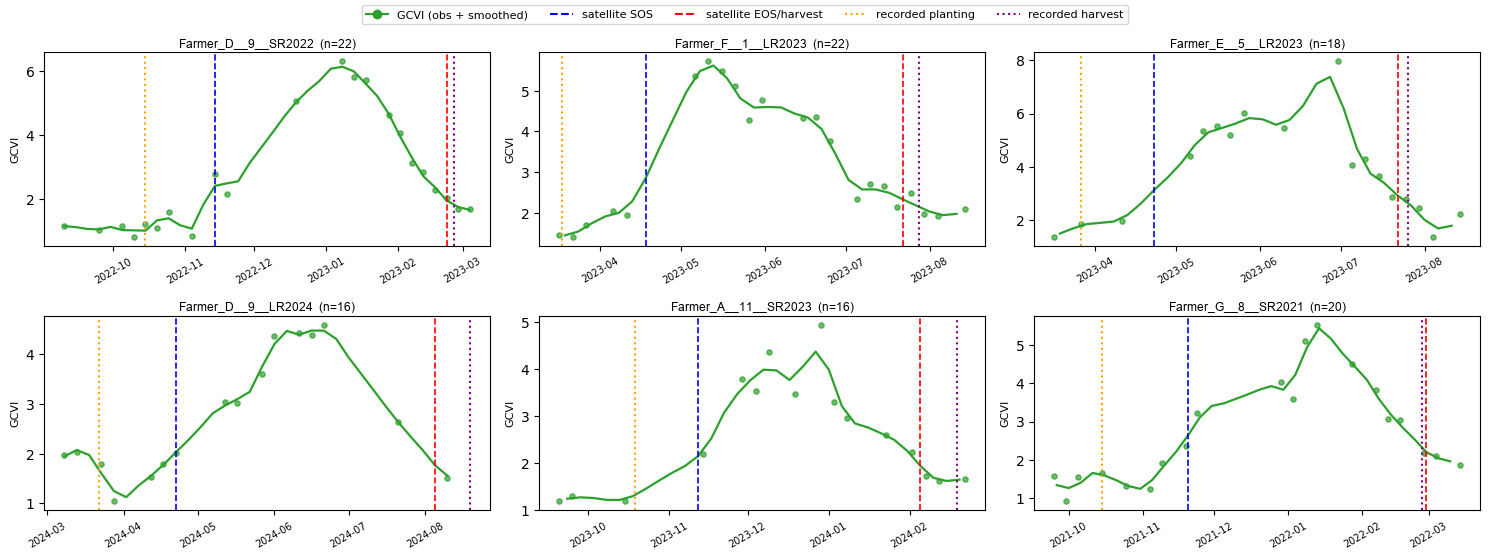

In [19]:
# NOTE: 'Farmer_X' labels are anonymized placeholders for the six example
# field-seasons shown below (format: <anonymized_id>__<field>__<season>).
# Replace with real fs_id values from your own `fs` dataframe to reproduce.
MAX_PANELS = None   # Not needed when explicitly defining plot_ids

plot_ids = [
    'Farmer_D__9__SR2022',
    'Farmer_F__1__LR2023',
    'Farmer_E__5__LR2023',
    'Farmer_D__9__LR2024',
    'Farmer_A__11__SR2023',
    'Farmer_G__8__SR2021'
]

ncol = 3; nrow = int(np.ceil(len(plot_ids) / ncol)) if plot_ids else 1
fig, axes = plt.subplots(nrow, ncol, figsize=(5 * ncol, 2.8 * nrow), squeeze=False)
axes = np.ravel(axes)
for ax, fid in zip(axes, plot_ids):
    row = fs[fs.fs_id == fid].iloc[0]; win = windows[str(row.season)]
    g2 = s2_df[s2_df.fs_id == fid].sort_values("date")
    grid, gcvi, obs, n = _resample_smooth(g2["date"], g2["GCVI"], *win, SAVGOL_WIN, 2, MIN_S2_OBS)
    ax.scatter(g2["date"], g2["GCVI"], s=14, color="tab:green", alpha=0.7)
    if grid is not None:
        ax.plot(grid[obs], gcvi[obs], color="tab:green", lw=1.6)
    e = eo[eo.fs_id == fid]
    if len(e):
        for k, c in [("sos", "blue"), ("eos", "red")]:
            v = e.iloc[0].get(k)
            if pd.notna(v):
                ax.axvline(v, color=c, ls="--", lw=1.2)
    if pd.notna(row["_plant"]):
        ax.axvline(row["_plant"], color="orange", ls=":", lw=1.5)
    if pd.notna(row["_harvest"]):
        ax.axvline(row["_harvest"], color="purple", ls=":", lw=1.5)
    ax.set_title(f"{fid}  (n={n})", fontsize=8)
    ax.tick_params(axis="x", rotation=30, labelsize=7); ax.set_ylabel("GCVI", fontsize=8)
for ax in axes[len(plot_ids):]:
    ax.axis("off")
from matplotlib.lines import Line2D
legend = [Line2D([0],[0], color="tab:green", marker="o", label="GCVI (obs + smoothed)"),
          Line2D([0],[0], color="blue", ls="--", label="satellite SOS"),
          Line2D([0],[0], color="red", ls="--", label="satellite EOS/harvest"),
          Line2D([0],[0], color="orange", ls=":", label="recorded planting"),
          Line2D([0],[0], color="purple", ls=":", label="recorded harvest")]
fig.legend(handles=legend, loc="upper center", ncol=5, fontsize=8)
fig.tight_layout(rect=[0, 0, 1, 0.97])
fig.savefig(f"{OUT_DIR}/fig3_per_plot_curves.png", dpi=200); plt.show()

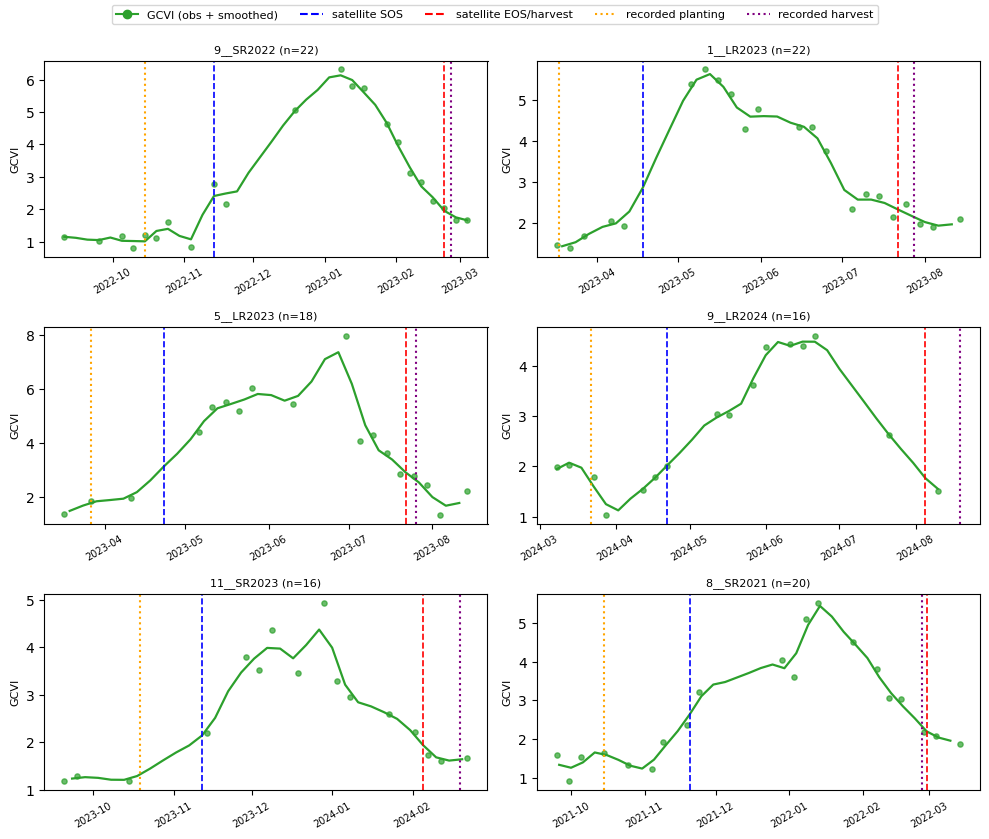

In [20]:
ncol = 2; nrow = int(np.ceil(len(plot_ids) / ncol)) if plot_ids else 1
fig, axes = plt.subplots(nrow, ncol, figsize=(5 * ncol, 2.8 * nrow), squeeze=False)
axes = np.ravel(axes)
for ax, fid in zip(axes, plot_ids):
    row = fs[fs.fs_id == fid].iloc[0]; win = windows[str(row.season)]
    g2 = s2_df[s2_df.fs_id == fid].sort_values("date")
    grid, gcvi, obs, n = _resample_smooth(g2["date"], g2["GCVI"], *win, SAVGOL_WIN, 2, MIN_S2_OBS)
    ax.scatter(g2["date"], g2["GCVI"], s=14, color="tab:green", alpha=0.7)
    if grid is not None:
        ax.plot(grid[obs], gcvi[obs], color="tab:green", lw=1.6)
    e = eo[eo.fs_id == fid]
    if len(e):
        for k, c in [("sos", "blue"), ("eos", "red")]:
            v = e.iloc[0].get(k)
            if pd.notna(v):
                ax.axvline(v, color=c, ls="--", lw=1.2)
    if pd.notna(row["_plant"]):
        ax.axvline(row["_plant"], color="orange", ls=":", lw=1.5)
    if pd.notna(row["_harvest"]):
        ax.axvline(row["_harvest"], color="purple", ls=":", lw=1.5)

    # Modify title to remove farmer name
    display_title = "__".join(fid.split("__")[1:])
    ax.set_title(f"{display_title} (n={n})", fontsize=8)
    ax.tick_params(axis="x", rotation=30, labelsize=7); ax.set_ylabel("GCVI", fontsize=8)
for ax in axes[len(plot_ids):]:
    ax.axis("off")
from matplotlib.lines import Line2D
legend = [Line2D([0],[0], color="tab:green", marker="o", label="GCVI (obs + smoothed)"),
          Line2D([0],[0], color="blue", ls="--", label="satellite SOS"),
          Line2D([0],[0], color="red", ls="--", label="satellite EOS/harvest"),
          Line2D([0],[0], color="orange", ls=":", label="recorded planting"),
          Line2D([0],[0], color="purple", ls=":", label="recorded harvest")]
fig.legend(handles=legend, loc="upper center", ncol=5, fontsize=8)
fig.tight_layout(rect=[0, 0, 1, 0.97])
fig.savefig(f"{OUT_DIR}/fig3_per_plot_curves_no_farmer.png", dpi=200); plt.show()


In [21]:
import os

# Get all available field-seasons with Sentinel-1 data
all_fs_ids = s1_df['fs_id'].unique()

if len(all_fs_ids) > 0:
    print(f"Extracting Sentinel-1 VH data for all {len(all_fs_ids)} plots to CSV...")
    for fid in all_fs_ids:
        # Get the data for this specific field-season
        g1 = s1_df[s1_df.fs_id == fid].sort_values("date")

        # Select relevant columns for the plot data
        extract_df = g1[["fs_id", "date", "VH"]].copy()

        # Create a safe filename
        safe_fid = fid.replace(" ", "_").replace("'", "").replace("/", "_")
        out_path = f"{OUT_DIR}/plot3b_data_{safe_fid}.csv"

        # Save to CSV
        extract_df.to_csv(out_path, index=False)

    print(f"Successfully saved {len(all_fs_ids)} CSV files to {OUT_DIR}")
else:
    print("No Sentinel-1 coverage available to extract.")

Extracting Sentinel-1 VH data for all 50 plots to CSV...
Successfully saved 50 CSV files to /content/eo_ofe_outputs


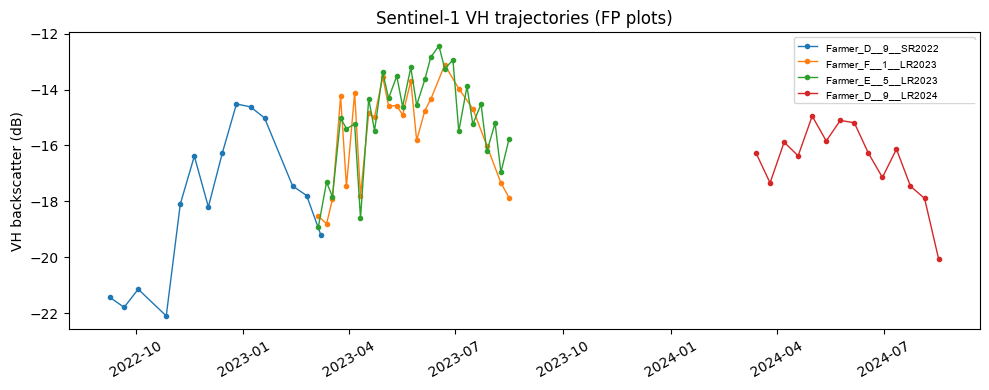

In [22]:
# Sentinel-1 VH trajectories for the same example plots (harvest shows as a backscatter drop)
ex_ids = [f for f in plot_ids if len(s1_df[s1_df.fs_id == f])][:4]
if ex_ids:
    fig, ax = plt.subplots(figsize=(10, 4))
    for fid in ex_ids:
        g1 = s1_df[s1_df.fs_id == fid].sort_values("date")
        ax.plot(g1["date"], g1["VH"], marker="o", ms=3, lw=1, label=fid)
    ax.set_ylabel("VH backscatter (dB)"); ax.set_title("Sentinel-1 VH trajectories (FP plots)")
    ax.legend(fontsize=7); ax.tick_params(axis="x", rotation=30)
    fig.tight_layout(); fig.savefig(f"{OUT_DIR}/fig3b_s1_vh.png", dpi=200); plt.show()
else:
    print("No Sentinel-1 coverage among the plotted field-seasons.")

In [23]:
cal = fs.merge(eo, on="fs_id", how="left")

def mean_date(a, b):
    vals = [x for x in [a, b] if pd.notna(x)]
    return pd.Series(vals).mean() if vals else pd.NaT

def radar_led(radar, optical):
    return radar if pd.notna(radar) else optical

# Start of season: sensor-led per SENSOR_LEAD_START, with the other sensor as fallback.
cal["start_optical"] = cal["sos"]
cal["start_radar"]   = cal["s1_sos"]
if SENSOR_LEAD_START == "optical":
    cal["start_consensus"] = cal["sos"].fillna(cal["s1_sos"])
    cal["start_source"]    = np.where(cal["sos"].notna(), "optical",
                              np.where(cal["s1_sos"].notna(), "radar", "none"))
else:
    cal["start_consensus"] = cal["s1_sos"].fillna(cal["sos"])
    cal["start_source"]    = np.where(cal["s1_sos"].notna(), "radar",
                              np.where(cal["sos"].notna(), "optical", "none"))
# Peak / tasseling: sensor-led per SENSOR_LEAD_PEAK; both sensors and the offset kept for reporting
if SENSOR_LEAD_PEAK == "optical":
    cal["peak_consensus"] = cal["peak"].fillna(cal["s1_peak"])
else:
    cal["peak_consensus"] = cal["s1_peak"].fillna(cal["peak"])
cal["peak_optical"]      = cal["peak"]
cal["peak_radar"]        = cal["s1_peak"]
cal["peak_offset_d"]     = (cal["s1_peak"] - cal["peak"]).dt.days
# Harvest: OPTICAL-LED (senescence is a chlorophyll signal; the radar drop is late and noisy
# because maize is often left standing to dry). Radar is a fallback only where optical is absent.
# Averaging the two, as earlier versions did, dragged a good estimate toward a poor one.
cal["harvest_optical"] = cal["eos"]
cal["harvest_radar"]   = cal["s1_harvest"]
cal["harvest_raw"]     = cal["eos"].fillna(cal["s1_harvest"])
cal["harvest_source"]  = np.where(cal["eos"].notna(), "optical",
                          np.where(cal["s1_harvest"].notna(), "radar", "none"))
cal["harvest_consensus"] = cal["harvest_raw"]   # refined by the calibrated lag in section 9b

# Initialize harvest_loo_err_d and topdress_loo_err_d to prevent KeyError if not populated later
# Initialize with np.nan to ensure a numeric type (float) for these columns
cal["harvest_loo_err_d"] = np.nan
cal["topdress_loo_err_d"] = np.nan

cal["sensors_agree_start"] = [
    (pd.notna(a) and pd.notna(b) and abs((a - b).days) <= SAT_AGREE_DAYS)
    for a, b in zip(cal["sos"], cal["s1_sos"])]

def dekad_diff(a, b):
    return (a - b).dt.days / 10.0

# start-of-season reported as an offset from recorded sowing (this dataset has no emergence)
cal["start_vs_sowing_dek"] = dekad_diff(cal["start_consensus"], cal["_plant"])
cal["s2_harvest_dek"]  = dekad_diff(cal["eos"], cal["_harvest"])
cal["s1_harvest_dek"]  = dekad_diff(cal["s1_harvest"], cal["_harvest"])
cal["harvest_vs_rec_dek"] = dekad_diff(cal["harvest_consensus"], cal["_harvest"])
# Interval from topdressing (about V6) to the canopy peak (about tasseling). This is a
# biological interval, roughly 30 to 50 days, NOT an error. Topdress timing is predicted
# separately in section 9c from the start-of-season.
cal["peak_minus_topdr_d"] = (cal["peak_consensus"] - cal["_topdress"]).dt.days

def agree(series):
    a = series.abs().dropna()
    if len(a) == 0:
        return dict(n=0, within1=np.nan, within2=np.nan, median_abs_d=np.nan, bias_d=np.nan)
    return dict(n=len(a), within1=round(float((a <= 1).mean()), 3),
                within2=round(float((a <= 2).mean()), 3),
                median_abs_d=round(float(a.median()) * 10, 1),
                bias_d=round(float(series.dropna().median()) * 10, 1))

cal["_weak"] = pd.to_numeric(cal["peak_GCVI"], errors="coerce") < WEAK_PEAK_GCVI
cal["_lowy"] = pd.to_numeric(cal["grain_kgha"], errors="coerce") < FAIL_YIELD_KGHA
cal["likely_fail"] = cal["_weak"] & cal["_lowy"]

n_both = int((cal["sos"].notna() & cal["s1_sos"].notna()).sum())
print(f"Field-seasons with BOTH sensors (start of season): {n_both}"
      + (f" | agree within {SAT_AGREE_DAYS} d: {int(cal['sensors_agree_start'].sum())}" if n_both else ""))

agreement = pd.DataFrame([
    {"stage": "harvest",             "estimator": "optical (S2)",  **agree(cal["s2_harvest_dek"])},
    {"stage": "harvest",             "estimator": "radar (S1)",    **agree(cal["s1_harvest_dek"])},
    {"stage": "harvest",             "estimator": "consensus",     **agree(cal["harvest_vs_rec_dek"])},
    {"stage": "harvest",             "estimator": "consensus (failure-cleaned)",
     **agree(cal.loc[~cal["likely_fail"], "harvest_vs_rec_dek"])},
])
agreement.to_csv(f"{OUT_DIR}/table_agreement_threeway.csv", index=False)
print("\nAgreement (median_abs_d and bias_d in days; within1/2 in dekads):\n" + agreement.to_string(index=False))
print("\nStart-of-season has no recorded ground truth here (no emergence column); it is checked by "
      "optical-radar agreement (Plot 4c) and by the seeding calibration (section 9).")

cal["calendar_flag"] = cal["harvest_vs_rec_dek"].abs() > 2
print("\nCalendar-flagged field-seasons:", int(cal["calendar_flag"].sum()))
_off = cal["peak_offset_d"].dropna()
print("Peak/tasseling resolved:", int(cal["peak_consensus"].notna().sum()),
      "| median optical->radar peak offset (d):", f"{np.median(_off):.0f}" if len(_off) else "n/a")
cal.to_csv(f"{OUT_DIR}/table_calendar_check.csv", index=False)


Field-seasons with BOTH sensors (start of season): 47 | agree within 21 d: 33

Agreement (median_abs_d and bias_d in days; within1/2 in dekads):
  stage                   estimator  n  within1  within2  median_abs_d  bias_d
harvest                optical (S2) 32    0.531    0.844           9.5    -6.5
harvest                  radar (S1) 39    0.256    0.410          24.0   -10.0
harvest                   consensus 39    0.538    0.846          10.0    -6.0
harvest consensus (failure-cleaned) 39    0.538    0.846          10.0    -6.0

Start-of-season has no recorded ground truth here (no emergence column); it is checked by optical-radar agreement (Plot 4c) and by the seeding calibration (section 9).

Calendar-flagged field-seasons: 6
Peak/tasseling resolved: 50 | median optical->radar peak offset (d): 25


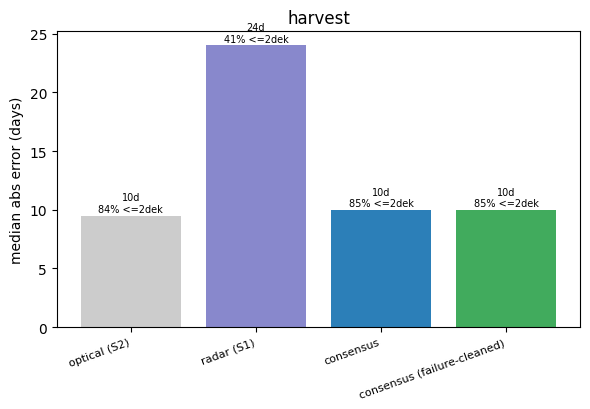

In [24]:
stages = list(dict.fromkeys(agreement["stage"]))
fig, ax = plt.subplots(1, len(stages), figsize=(6 * len(stages), 4.2), squeeze=False)
ax = ax[0]
for a, stage in zip(ax, stages):
    d = agreement[agreement.stage == stage]
    x = np.arange(len(d))
    a.bar(x, d["median_abs_d"], color=["#cccccc", "#8888cc", "#2c7fb8", "#41ab5d"][:len(d)])
    a.set_xticks(x); a.set_xticklabels(d["estimator"], rotation=20, ha="right", fontsize=8)
    a.set_ylabel("median abs error (days)"); a.set_title(stage)
    for xi, (m, w) in enumerate(zip(d["median_abs_d"], d["within2"])):
        if pd.notna(m): a.text(xi, m + 0.3, f"{m:.0f}d\n{w:.0%} <=2dek", ha="center", fontsize=7)
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/fig4_0_agreement.png", dpi=200); plt.show()

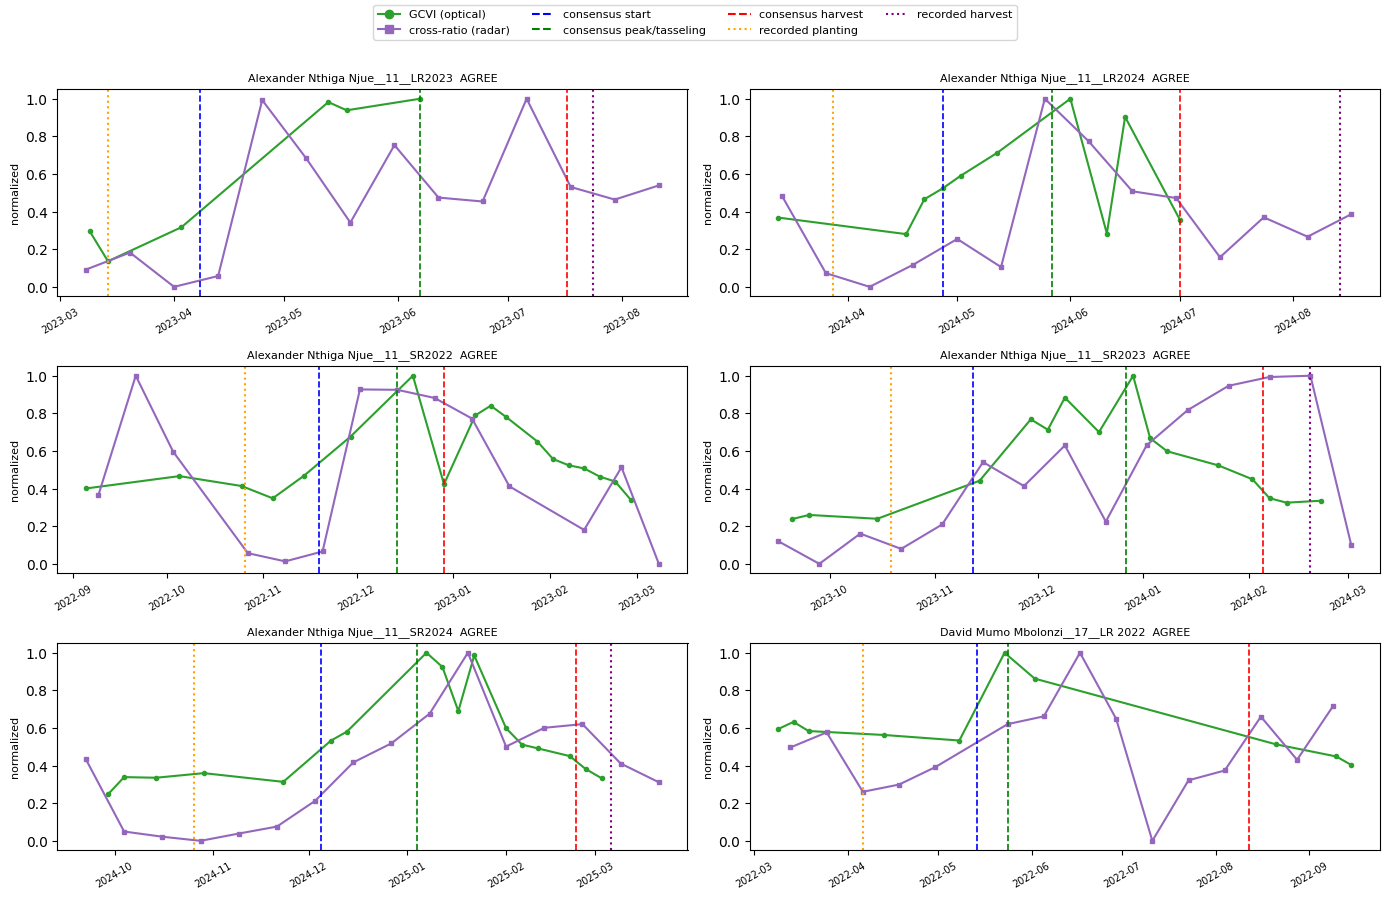

In [25]:
dual_ids = [f for f in cal.fs_id
            if len(s1_df[s1_df.fs_id == f]) >= MIN_S1_OBS
            and len(s2_df[s2_df.fs_id == f]) >= MIN_S2_OBS][:6]
if dual_ids:
    ncol = 2; nrow = int(np.ceil(len(dual_ids) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(7 * ncol, 3 * nrow), squeeze=False)
    axes = np.ravel(axes)
    for ax, fid in zip(axes, dual_ids):
        row = fs[fs.fs_id == fid].iloc[0]
        g2 = s2_df[s2_df.fs_id == fid].sort_values("date")
        g1 = s1_df[s1_df.fs_id == fid].sort_values("date")
        if g2["GCVI"].max() > 0:
            ax.plot(g2["date"], g2["GCVI"] / g2["GCVI"].max(),
                    color="tab:green", marker="o", ms=3, label="GCVI (optical)")
        cr = g1["VH_VV"]
        if cr.max() > cr.min():
            ax.plot(g1["date"], (cr - cr.min()) / (cr.max() - cr.min()),
                    color="tab:purple", marker="s", ms=3, label="cross-ratio (radar)")
        e = cal[cal.fs_id == fid].iloc[0]
        for k, c in [("start_consensus", "blue"), ("peak_consensus", "green"), ("harvest_consensus", "red")]:
            if pd.notna(e.get(k)): ax.axvline(e[k], color=c, ls="--", lw=1.2)
        if pd.notna(row["_plant"]):   ax.axvline(row["_plant"], color="orange", ls=":", lw=1.5)
        if pd.notna(row["_harvest"]): ax.axvline(row["_harvest"], color="purple", ls=":", lw=1.5)
        tag = "  AGREE" if e.get("sensors_agree_start") else ""
        ax.set_title(f"{fid}{tag}", fontsize=8)
        ax.tick_params(axis="x", rotation=30, labelsize=7); ax.set_ylabel("normalized", fontsize=8)
    for ax in axes[len(dual_ids):]:
        ax.axis("off")
    fig.legend(handles=[
        Line2D([0],[0], color="tab:green", marker="o", label="GCVI (optical)"),
        Line2D([0],[0], color="tab:purple", marker="s", label="cross-ratio (radar)"),
        Line2D([0],[0], color="blue", ls="--", label="consensus start"),
        Line2D([0],[0], color="green", ls="--", label="consensus peak/tasseling"),
        Line2D([0],[0], color="red", ls="--", label="consensus harvest"),
        Line2D([0],[0], color="orange", ls=":", label="recorded planting"),
        Line2D([0],[0], color="purple", ls=":", label="recorded harvest")],
        loc="upper center", ncol=4, fontsize=8)
    fig.tight_layout(rect=[0, 0, 1, 0.94])
    fig.savefig(f"{OUT_DIR}/fig4a_dual_sensor_calendar.png", dpi=200); plt.show()
else:
    print("No field-seasons have both enough S1 and enough S2 dates to compare.")

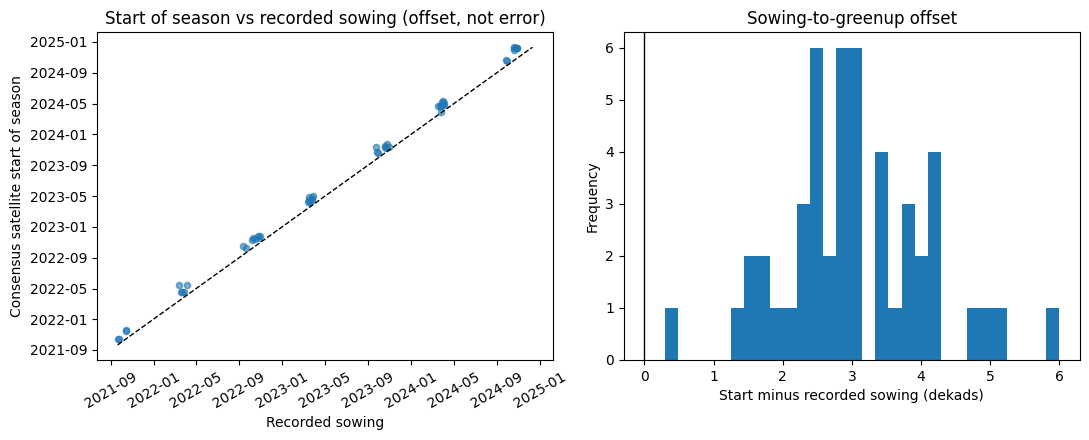

Compared field-seasons: 49


In [26]:
sub = cal.dropna(subset=["_plant", "start_consensus"])
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
if len(sub):
    ax[0].scatter(sub["_plant"], sub["start_consensus"], s=20, alpha=0.6)
    lims = [min(sub["_plant"].min(), sub["start_consensus"].min()),
            max(sub["_plant"].max(), sub["start_consensus"].max())]
    ax[0].plot(lims, lims, "k--", lw=1)
    ax[0].tick_params(axis="x", rotation=30)
else:
    ax[0].text(0.5, 0.5, "No recorded sowing dates\nto compare against", ha="center", va="center")
ax[0].set_xlabel("Recorded sowing"); ax[0].set_ylabel("Consensus satellite start of season")
ax[0].set_title("Start of season vs recorded sowing (offset, not error)")
h = cal["start_vs_sowing_dek"].dropna()
if len(h):
    h.plot.hist(bins=30, ax=ax[1])
ax[1].axvline(0, color="k", lw=1); ax[1].set_xlabel("Start minus recorded sowing (dekads)")
ax[1].set_title("Sowing-to-greenup offset")
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/fig4b_start_vs_sowing.png", dpi=200); plt.show()
print("Compared field-seasons:", len(sub))

In [27]:
# Head-to-head: which SOS source gives the most repeatable lag to recorded sowing?
def _sos_report(col, label):
    lag = (cal[col] - cal["_plant"]).dt.days.dropna()
    if len(lag) == 0:
        return dict(source=label, n=0)
    ok = lag[(lag >= 0) & (lag <= 60)]
    return dict(source=label, n=len(lag),
                lag_median_d=round(float(lag.median()), 1),
                lag_IQR_width_d=round(float(lag.quantile(.75) - lag.quantile(.25)), 1),
                plausible_pct=round(100 * len(ok) / len(lag), 0))

_rows = [_sos_report("start_optical", "optical (S2 GCVI)"),
         _sos_report("start_radar",   "radar (S1 cross-ratio)"),
         _sos_report("start_consensus", f"consensus ({SENSOR_LEAD_START}-led)")]
sos_choice = pd.DataFrame(_rows)
sos_choice.to_csv(f"{OUT_DIR}/table_sos_sensor_choice.csv", index=False)
print("Start-of-season lag to recorded sowing, by sensor:")
print(sos_choice.to_string(index=False))
print("\nA NARROWER lag IQR means a more repeatable offset, which is what the seeding model needs.")
_neg = (cal["start_consensus"] - cal["_plant"]).dt.days
_nneg = int((_neg < 0).sum())
print(f"Green-up detected BEFORE recorded sowing (physically impossible): {_nneg} of "
      f"{int(_neg.notna().sum())} field-seasons")
if _nneg:
    print("  Each of these is a detection failure, not a scatter point. If the count is not near")
    print("  zero, the start-of-season detector is firing on something other than the crop.")
_o = (cal["start_radar"] - cal["start_optical"]).dt.days.dropna()
if len(_o):
    print(f"radar minus optical SOS: median {_o.median():+.0f} d, sd {_o.std():.0f} d "
          f"(a real structural-vs-greenness offset would be a consistent +10 to +14 d; "
          f"a large sd means the radar detector is not tracking a repeatable event here)")
print(f"start source used: {pd.Series(cal['start_source']).value_counts().to_dict()}")

Start-of-season lag to recorded sowing, by sensor:
                 source  n  lag_median_d  lag_IQR_width_d  plausible_pct
      optical (S2 GCVI) 49          29.0             14.0          100.0
 radar (S1 cross-ratio) 46          27.0             23.8           76.0
consensus (optical-led) 49          29.0             14.0          100.0

A NARROWER lag IQR means a more repeatable offset, which is what the seeding model needs.
Green-up detected BEFORE recorded sowing (physically impossible): 0 of 49 field-seasons
radar minus optical SOS: median -5 d, sd 25 d (a real structural-vs-greenness offset would be a consistent +10 to +14 d; a large sd means the radar detector is not tracking a repeatable event here)
start source used: {'optical': 50}


Cross-sensor SOS: agree 33/47 within 21 d | median S1-S2 offset -5 d (IQR -18 to +10 d)


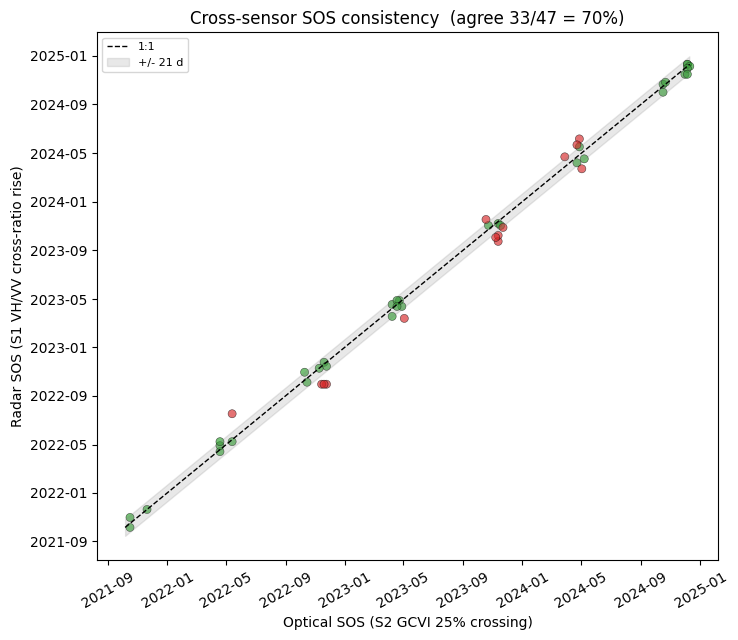

In [28]:
both = cal.dropna(subset=["sos", "s1_sos"]).copy()
fig, ax = plt.subplots(figsize=(7.5, 6.5))
if len(both):
    colors = both["sensors_agree_start"].map({True: "tab:green", False: "tab:red"})
    ax.scatter(both["sos"], both["s1_sos"], s=34, alpha=0.65, c=colors, edgecolor="k", lw=0.4)
    lims = [min(both["sos"].min(), both["s1_sos"].min()),
            max(both["sos"].max(), both["s1_sos"].max())]
    ax.plot(lims, lims, "k--", lw=1, label="1:1")
    xs = pd.date_range(lims[0], lims[1], freq="5D")
    ax.fill_between(xs, xs - pd.Timedelta(days=SAT_AGREE_DAYS), xs + pd.Timedelta(days=SAT_AGREE_DAYS),
                    color="gray", alpha=0.18, label=f"+/- {SAT_AGREE_DAYS} d")
    n_agree = int(both["sensors_agree_start"].sum())
    off = (both["s1_sos"] - both["sos"]).dt.days
    ax.set_title(f"Cross-sensor SOS consistency  "
                 f"(agree {n_agree}/{len(both)} = {100*n_agree/len(both):.0f}%)")
    ax.legend(loc="upper left", fontsize=8)
    print(f"Cross-sensor SOS: agree {n_agree}/{len(both)} within {SAT_AGREE_DAYS} d | "
          f"median S1-S2 offset {off.median():+.0f} d "
          f"(IQR {off.quantile(.25):+.0f} to {off.quantile(.75):+.0f} d)")
else:
    ax.text(0.5, 0.5, "No field-seasons with both S1 and S2 SOS",
            ha="center", va="center", transform=ax.transAxes)
    print("Cross-sensor SOS: no field-seasons with both sensors.")
ax.set_xlabel("Optical SOS (S2 GCVI 25% crossing)")
ax.set_ylabel("Radar SOS (S1 VH/VV cross-ratio rise)")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/fig4c_cross_sensor_sos.png", dpi=200); plt.show()

In [29]:
chk = cal.merge(anc_df, on="fs_id", how="left")

for col in ["grain_kgha", "stover_kgha"]:
    v = pd.to_numeric(chk[col], errors="coerce")
    if v.notna().any():
        mx = v.max()
        flag = "  <-- looks like t/ha, CHECK" if (pd.notna(mx) and mx < 50) else ""
        print(f"{col}: median {v.median():.0f}, max {mx:.0f} kg/ha{flag}")

g = pd.to_numeric(chk["grain_kgha"], errors="coerce")
st = pd.to_numeric(chk["stover_kgha"], errors="coerce")
chk["harvest_index"] = g / (g + st)
hi = chk["harvest_index"].dropna()
if len(hi):
    print(f"Harvest index: median {hi.median():.2f} (maize expected ~0.40-0.55, dry-weight basis); "
          f"out-of-range field-seasons: {int(((hi<0.2)|(hi>0.7)).sum())}")

grain_kgha: median 2735, max 6522 kg/ha
stover_kgha: median 3504, max 7745 kg/ha
Harvest index: median 0.45 (maize expected ~0.40-0.55, dry-weight basis); out-of-range field-seasons: 2


In [30]:
# Crop-failure / stress signal, plus a terrain caution for the SAR estimates
chk["weak_canopy"] = pd.to_numeric(chk.get("peak_GCVI"), errors="coerce") < WEAK_PEAK_GCVI
chk["low_yield"]   = pd.to_numeric(chk["grain_kgha"], errors="coerce") < FAIL_YIELD_KGHA
chk["likely_fail"] = chk["weak_canopy"] & chk["low_yield"]
chk["fail_explains_calendar"] = chk["likely_fail"] & chk["calendar_flag"]
chk["steep_terrain"] = pd.to_numeric(chk.get("slope_deg"), errors="coerce") > SLOPE_SCREEN_DEG

print("Weak canopy (peak GCVI < {}): {}".format(WEAK_PEAK_GCVI, int(chk["weak_canopy"].sum())))
print("Low recorded grain yield (< {} kg/ha): {}".format(FAIL_YIELD_KGHA, int(chk["low_yield"].sum())))
print("Likely failed/stressed crop (both): {}".format(int(chk["likely_fail"].sum())))
print("...also calendar-flagged (failure explains the odd calendar): {}".format(int(chk["fail_explains_calendar"].sum())))
print("On steep terrain (slope > {} deg, treat SAR dates with caution): {}".format(
    SLOPE_SCREEN_DEG, int(chk["steep_terrain"].sum())))
chk.to_csv(f"{OUT_DIR}/table_calendar_and_yield_check.csv", index=False)

Weak canopy (peak GCVI < 1.5): 0
Low recorded grain yield (< 1000 kg/ha): 2
Likely failed/stressed crop (both): 0
...also calendar-flagged (failure explains the odd calendar): 0
On steep terrain (slope > 15 deg, treat SAR dates with caution): 0


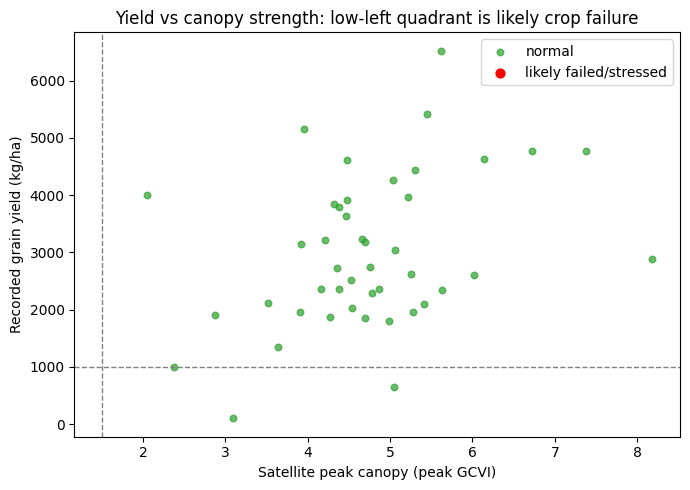

In [31]:
fig, ax = plt.subplots(figsize=(7, 5))
d = chk.dropna(subset=["peak_GCVI", "grain_kgha"])
normal = d[~d["likely_fail"]]; fail = d[d["likely_fail"]]
ax.scatter(normal["peak_GCVI"], normal["grain_kgha"], s=22, color="tab:green", alpha=0.7, label="normal")
ax.scatter(fail["peak_GCVI"], fail["grain_kgha"], s=40, color="red", label="likely failed/stressed")
ax.axhline(FAIL_YIELD_KGHA, color="gray", ls="--", lw=1)
ax.axvline(WEAK_PEAK_GCVI, color="gray", ls="--", lw=1)
ax.set_xlabel("Satellite peak canopy (peak GCVI)"); ax.set_ylabel("Recorded grain yield (kg/ha)")
ax.set_title("Yield vs canopy strength: low-left quadrant is likely crop failure")
ax.legend(); fig.tight_layout(); fig.savefig(f"{OUT_DIR}/fig5_yield_vs_canopy.png", dpi=200); plt.show()

In [32]:
import numpy as np
# Calibrate the start-of-season -> sowing lag on field-seasons with a recorded sowing date
lag_all = (cal["start_consensus"] - cal["_plant"]).dt.days
lag_valid = lag_all[(lag_all >= 0) & (lag_all <= 60)].dropna()

if len(lag_valid) >= MIN_CALIB_N:
    lag_med = float(lag_valid.median())
    lag_lo, lag_hi = float(lag_valid.quantile(0.25)), float(lag_valid.quantile(0.75))
    src = f"calibrated on n={len(lag_valid)} recorded sowings"
else:
    lag_med, lag_lo, lag_hi = map(float, FALLBACK_LAG)
    src = f"FALLBACK default ({len(lag_valid)} recorded sowings < MIN_CALIB_N={MIN_CALIB_N})"
print(f"SOS->sowing lag [{src}]: median {lag_med:.0f} d, IQR {lag_lo:.0f}-{lag_hi:.0f} d")

# Apply to every field-season: a point estimate and an IQR bracket for the implied sowing date
cal["seed_consensus"] = cal["start_consensus"] - pd.to_timedelta(lag_med, unit="D")
cal["seed_early"]     = cal["start_consensus"] - pd.to_timedelta(lag_hi, unit="D")
cal["seed_late"]      = cal["start_consensus"] - pd.to_timedelta(lag_lo, unit="D")

# Leave-one-out validation on fields that DO have a recorded sowing (no circularity)
loo_err = []
for i in lag_valid.index:
    others = lag_valid.drop(i)
    if len(others) < 3:
        continue
    implied = cal.loc[i, "start_consensus"] - pd.Timedelta(days=float(others.median()))
    loo_err.append((implied - cal.loc[i, "_plant"]).days)
loo_err = np.array(loo_err, dtype=float)

cal["recorded_seed_in_bracket"] = [
    (pd.notna(e) and pd.notna(l) and pd.notna(s) and e <= s <= l)
    for e, l, s in zip(cal["seed_early"], cal["seed_late"], cal["_plant"])]

# Error on EVERY field-season with a recorded sowing, using the calibrated lag. The LOO figure
# below is computed only on the calibration subset (lag inside the plausible window), which
# excludes the field-seasons where the start-of-season detection failed; reporting only that
# number would understate the error on the full sample.
_seed_all = (cal["seed_consensus"] - cal["_plant"]).dt.days.dropna()
if len(_seed_all):
    print(f"Seeding error on ALL field-seasons with a recorded sowing (n={len(_seed_all)}): "
          f"median abs {_seed_all.abs().median():.1f} d, bias {_seed_all.median():+.0f} d")

n_start = int(cal["start_consensus"].notna().sum())
n_missing_seed = int(cal["_plant"].isna().sum())
n_fillable = int(cal.loc[cal["_plant"].isna(), "seed_consensus"].notna().sum())
print(f"Field-seasons with a satellite start-of-season: {n_start}")
if len(loo_err):
    print(f"LOO seeding error (days): median abs {np.nanmedian(np.abs(loo_err)):.1f}, "
          f"bias {np.nanmean(loo_err):+.1f}, within 1 dekad {(np.abs(loo_err) <= 10).mean():.0%} (n={len(loo_err)})")
print(f"Recorded sowing inside calibrated bracket: "
      f"{int(cal['recorded_seed_in_bracket'].sum())} of {int(cal['_plant'].notna().sum())}")
print(f"Missing sowing dates the model can gap-fill: {n_fillable} of {n_missing_seed}")
cal.to_csv(f"{OUT_DIR}/table_calendar_check.csv", index=False)

# Display relevant columns to debug seed_consensus population
display(cal[['_plant', 'start_consensus', 'seed_consensus']].head())

SOS->sowing lag [calibrated on n=49 recorded sowings]: median 29 d, IQR 24-38 d
Seeding error on ALL field-seasons with a recorded sowing (n=49): median abs 6.0 d, bias +0 d
Field-seasons with a satellite start-of-season: 50
LOO seeding error (days): median abs 7.0, bias +0.9, within 1 dekad 65% (n=49)
Recorded sowing inside calibrated bracket: 27 of 49
Missing sowing dates the model can gap-fill: 1 of 1


,_plant,start_consensus,seed_consensus
0,2023-03-14,2023-04-08,2023-03-10
1,2024-03-28,2024-04-27,2024-03-29
2,2022-10-26,2022-11-19,2022-10-21
3,2023-10-19,2023-11-12,2023-10-14
4,2024-10-26,2024-12-05,2024-11-06


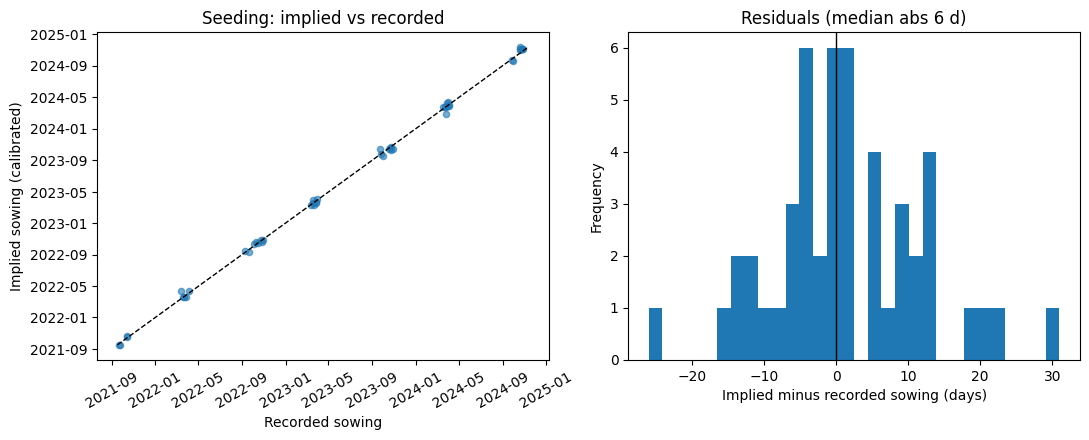

In [33]:
# Seeding validation figure: implied sowing vs recorded, with residuals in days
sub = cal.dropna(subset=["_plant", "seed_consensus"])
if len(sub):
    resid = (sub["seed_consensus"] - sub["_plant"]).dt.days
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
    ax[0].scatter(sub["_plant"], sub["seed_consensus"], s=20, alpha=0.6)
    lims = [min(sub["_plant"].min(), sub["seed_consensus"].min()),
            max(sub["_plant"].max(), sub["seed_consensus"].max())]
    ax[0].plot(lims, lims, "k--", lw=1)
    ax[0].set_xlabel("Recorded sowing"); ax[0].set_ylabel("Implied sowing (calibrated)")
    ax[0].set_title("Seeding: implied vs recorded"); ax[0].tick_params(axis="x", rotation=30)
    resid.plot.hist(bins=30, ax=ax[1]); ax[1].axvline(0, color="k", lw=1)
    ax[1].set_xlabel("Implied minus recorded sowing (days)")
    ax[1].set_title(f"Residuals (median abs {resid.abs().median():.0f} d)")
    fig.tight_layout(); fig.savefig(f"{OUT_DIR}/fig6_seeding_agreement.png", dpi=200); plt.show()
else:
    print("No field-seasons with both a recorded sowing and an implied seeding date.")

In [34]:
# Calibrate the EOS -> harvest lag on field-seasons with a recorded harvest
_hl_all = (cal["_harvest"] - cal["harvest_raw"]).dt.days
_hl = _hl_all[(_hl_all >= HARV_LAG_MIN_D) & (_hl_all <= HARV_LAG_MAX_D)].dropna()

if len(_hl) >= MIN_HARV_CALIB_N:
    harv_lag = float(_hl.median())
    hsrc = f"calibrated on n={len(_hl)} recorded harvests"
else:
    harv_lag = float(FALLBACK_HARV_LAG)
    hsrc = f"FALLBACK ({len(_hl)} < MIN_HARV_CALIB_N={MIN_HARV_CALIB_N})"
print(f"Senescence(EOS) -> harvest lag [{hsrc}]: median {harv_lag:+.0f} d "
      f"(IQR {_hl.quantile(.25):+.0f} to {_hl.quantile(.75):+.0f} d)" if len(_hl) else
      f"Senescence -> harvest lag [{hsrc}]: {harv_lag:+.0f} d")

cal["harvest_consensus"] = cal["harvest_raw"] + pd.to_timedelta(harv_lag, unit="D")
cal["harvest_vs_rec_dek"] = dekad_diff(cal["harvest_consensus"], cal["_harvest"])

# Leave-one-out validation (no circularity)
_loo_h = {}
for i in _hl.index:
    o = _hl.drop(i)
    if len(o) >= 3:
        pred = cal.loc[i, "harvest_raw"] + pd.Timedelta(days=float(o.median()))
        _loo_h[cal.loc[i, "fs_id"]] = (pred - cal.loc[i, "_harvest"]).days
cal["harvest_loo_err_d"] = cal["fs_id"].map(_loo_h)

_raw = (cal["harvest_raw"] - cal["_harvest"]).dt.days.dropna()
_e = pd.Series(list(_loo_h.values()), dtype=float)
print(f"  raw optical-led (no lag): median abs {_raw.abs().median():.1f} d, bias {_raw.median():+.0f} d (n={len(_raw)})")
if len(_e):
    print(f"  + calibrated lag (LOO):   median abs {_e.abs().median():.1f} d, bias {_e.mean():+.1f} d, "
          f"within 1 dekad {(_e.abs() <= 10).mean():.0%} (n={len(_e)})")
print("  harvest source:", cal["harvest_source"].value_counts().to_dict())

# ---- Second route: sowing estimate + calibrated crop cycle length ----
_cyc_all = (cal["_harvest"] - cal["_plant"]).dt.days
_cyc = _cyc_all[(_cyc_all >= CYCLE_CALIB_MIN_D) & (_cyc_all <= CYCLE_CALIB_MAX_D)].dropna()
if len(_cyc) >= MIN_CYCLE_CALIB_N:
    cyc_med = float(_cyc.median()); csrc = f"calibrated on n={len(_cyc)}"
else:
    cyc_med = float(FALLBACK_CYCLE_D); csrc = f"FALLBACK ({len(_cyc)} < {MIN_CYCLE_CALIB_N})"
print(f"\nCrop cycle length [{csrc}]: median {cyc_med:.0f} d, sd {_cyc.std():.1f} d"
      if len(_cyc) else f"\nCrop cycle length [{csrc}]: {cyc_med:.0f} d")
if "seed_consensus" in cal.columns:
    cal["harvest_agronomic"] = cal["seed_consensus"] + pd.to_timedelta(cyc_med, unit="D")
    # leave-one-out on the cycle length, so the comparison is not circular
    _loo_c = {}
    for i in _cyc.index:
        o = _cyc.drop(i)
        if len(o) >= 3 and pd.notna(cal.loc[i, "seed_consensus"]):
            pred = cal.loc[i, "seed_consensus"] + pd.Timedelta(days=float(o.median()))
            _loo_c[cal.loc[i, "fs_id"]] = (pred - cal.loc[i, "_harvest"]).days
    cal["harvest_agro_loo_err_d"] = cal["fs_id"].map(_loo_c)
    _ea = pd.Series(list(_loo_h.values()), dtype=float)
    _eb = pd.Series(list(_loo_c.values()), dtype=float)
    print("\nHarvest, two routes (leave-one-out):")
    if len(_ea):
        print(f"  (a) EOS + senescence lag   [EO-independent]  median abs {_ea.abs().median():4.1f} d, "
              f"bias {_ea.mean():+.1f} d, n={len(_ea)}")
    if len(_eb):
        print(f"  (b) sowing + cycle length  [NOT independent] median abs {_eb.abs().median():4.1f} d, "
              f"bias {_eb.mean():+.1f} d, n={len(_eb)}")
    print("  (b) is the better gap-filler; (a) is the honest EO detection claim. Report both and")
    print("  say which is which: (b) adds a constant to the sowing estimate and sees no senescence.")

    # Why (a) trails (b): the senescence-to-harvest lag is a FARMER habit, not a constant.
    _fl = cal.assign(_lag=(cal["_harvest"] - cal["harvest_raw"]).dt.days)
    _fl = _fl[_fl["_lag"].between(HARV_LAG_MIN_D, HARV_LAG_MAX_D)]
    if _fl["farmer"].nunique() > 2:
        _bf = _fl.groupby("farmer")["_lag"].median()
        print(f"\n  Senescence-to-harvest lag by farmer: median ranges {_bf.min():+.0f} to "
              f"{_bf.max():+.0f} d across {len(_bf)} farmers (spread of medians {_bf.std():.1f} d)")
        print("  That spread is a real farmer habit: some harvest promptly once the canopy browns,")
        print("  others leave the crop standing to dry. It is why (a) trails (b): sowing and crop")
        print("  duration are biology, but when a farmer walks into the field is a decision. With")
        print("  only a handful of harvests per farmer the habit is measurable but too noisy to")
        print("  calibrate per farmer, so a global lag is used. Report it as a limit of EO harvest")
        print("  detection, not as an error to tune away.")
else:
    cal["harvest_agronomic"] = pd.NaT
    cal["harvest_agro_loo_err_d"] = np.nan
    print("  (seed_consensus absent: run section 9 first for the agronomic harvest route)")

# The agreement table in section 7 is built BEFORE this lag is applied, so its harvest rows carry
# the pre-lag bias. Rebuild those rows here so the reported table matches the estimator in use.
try:
    _fixed = agreement.copy()
    _m = _fixed["stage"] == "harvest"
    if _m.any():
        for _est, _ser, _rows in [
                ("optical (S2)", cal["harvest_optical"], slice(None)),
                ("radar (S1)", cal["harvest_radar"], slice(None)),
                ("consensus", cal["harvest_consensus"], slice(None)),
                # the failure-cleaned row was previously left out of this rebuild, so it kept
                # reporting the PRE-lag harvest. With no flagged failures it must equal the
                # consensus row exactly; any difference was an artefact, not a result.
                ("consensus (failure-cleaned)", cal["harvest_consensus"], ~cal["likely_fail"])]:
            _sel = _m & (_fixed["estimator"] == _est)
            if _sel.any():
                _d = dekad_diff(_ser, cal["_harvest"])
                if not isinstance(_rows, slice):
                    _d = _d[_rows]
                for _k, _v in agree(_d).items():
                    _fixed.loc[_sel, _k] = _v
        agreement = _fixed
        agreement.to_csv(f"{OUT_DIR}/table_agreement_threeway.csv", index=False)
        print("\nAgreement table rebuilt with the post-lag harvest consensus:")
        print(agreement[agreement["stage"] == "harvest"].to_string(index=False))
except NameError:
    pass

Senescence(EOS) -> harvest lag [calibrated on n=39 recorded harvests]: median +6 d (IQR -3 to +15 d)
  raw optical-led (no lag): median abs 10.0 d, bias -6 d (n=39)
  + calibrated lag (LOO):   median abs 9.0 d, bias -0.8 d, within 1 dekad 54% (n=39)
  harvest source: {'optical': 42, 'radar': 8}

Crop cycle length [calibrated on n=39]: median 130 d, sd 9.0 d

Harvest, two routes (leave-one-out):
  (a) EOS + senescence lag   [EO-independent]  median abs  9.0 d, bias -0.8 d, n=39
  (b) sowing + cycle length  [NOT independent] median abs  4.0 d, bias +0.7 d, n=39
  (b) is the better gap-filler; (a) is the honest EO detection claim. Report both and
  say which is which: (b) adds a constant to the sowing estimate and sees no senescence.

  Senescence-to-harvest lag by farmer: median ranges -15 to +16 d across 8 farmers (spread of medians 10.3 d)
  That spread is a real farmer habit: some harvest promptly once the canopy browns,
  others leave the crop standing to dry. It is why (a) trails (b

In [35]:
# Screen implausible topdress records, then calibrate the SOS -> topdress lag
_td_sow = (cal["_topdress"] - cal["_plant"]).dt.days
_td_ok = _td_sow.between(TOPDRESS_MIN_D, TOPDRESS_MAX_D)
print(f"Topdress records: {int(_td_sow.notna().sum())} present, "
      f"{int(_td_ok.sum())} plausible ({TOPDRESS_MIN_D}-{TOPDRESS_MAX_D} d after sowing), "
      f"{int((_td_sow.notna() & ~_td_ok).sum())} screened out")
if _td_ok.any():
    print(f"  farmers topdress at sowing +{_td_sow[_td_ok].median():.0f} d "
          f"(IQR {_td_sow[_td_ok].quantile(.25):.0f}-{_td_sow[_td_ok].quantile(.75):.0f} d), "
          f"consistent with V6")

_tl_all = (cal["_topdress"] - cal["start_consensus"]).dt.days.where(_td_ok)
_tl = _tl_all[(_tl_all >= TD_LAG_MIN_D) & (_tl_all <= TD_LAG_MAX_D)].dropna()
if len(_tl) >= MIN_TD_CALIB_N:
    td_lag = float(_tl.median()); tsrc = f"calibrated on n={len(_tl)}"
else:
    td_lag = float(FALLBACK_TD_LAG); tsrc = f"FALLBACK ({len(_tl)} < {MIN_TD_CALIB_N})"
print(f"SOS -> topdress lag [{tsrc}]: median {td_lag:+.0f} d"
      + (f" (IQR {_tl.quantile(.25):+.0f} to {_tl.quantile(.75):+.0f} d)" if len(_tl) else ""))

cal["topdress_pred"] = cal["start_consensus"] + pd.to_timedelta(td_lag, unit="D")

# Optional: snap the prediction to the nearest TAMSAT rain day
def _snap_to_rain(pred, lat, lon, ds, rain, latn, lonn, tn):
    if pd.isna(pred):
        return pred
    lo, hi = pred - pd.Timedelta(days=RAIN_SNAP_WINDOW_D), pred + pd.Timedelta(days=RAIN_SNAP_WINDOW_D)
    try:
        da = ds[rain].sel({tn: slice(lo.strftime("%Y-%m-%d"), hi.strftime("%Y-%m-%d"))})
        if da[tn].size == 0:
            return pred
        v = da.sel({latn: float(lat), lonn: float(lon)}, method="nearest")
        vals = np.asarray(v.values, dtype="float64").ravel()
        days = pd.to_datetime(np.asarray(v[tn].values))
        wet = np.where(vals >= TOPDRESS_RAIN_MM)[0]
        if len(wet) == 0:
            return pred
        return days[wet[np.argmin(np.abs((days[wet] - pred).days))]]
    except Exception:
        return pred

if RAIN_SNAP and os.path.exists(TAMSAT_PATH):
    _ds, _R, _LA, _LO, _TN = _open_tamsat(TAMSAT_PATH)
    cal["topdress_pred_snapped"] = [
        _snap_to_rain(p, la, lo, _ds, _R, _LA, _LO, _TN)
        for p, la, lo in zip(cal["topdress_pred"], cal["lat"], cal["lon"])]
    _ds.close()
    _moved = (cal["topdress_pred_snapped"] != cal["topdress_pred"]).sum()
    print(f"Rain-snap: moved {int(_moved)} predictions to a TAMSAT day with "
          f">= {TOPDRESS_RAIN_MM} mm within +/- {RAIN_SNAP_WINDOW_D} d")
    cal["topdress_pred"] = cal["topdress_pred_snapped"]
elif RAIN_SNAP:
    print(f"RAIN_SNAP is on but TAMSAT not found at {TAMSAT_PATH}; prediction left unsnapped.")

# Leave-one-out validation of the topdress prediction
_loo_t = {}
for i in _tl.index:
    o = _tl.drop(i)
    if len(o) >= 3:
        pred = cal.loc[i, "start_consensus"] + pd.Timedelta(days=float(o.median()))
        _loo_t[cal.loc[i, "fs_id"]] = (pred - cal.loc[i, "_topdress"]).days
cal["topdress_loo_err_d"] = cal["fs_id"].map(_loo_t)
_e = pd.Series(list(_loo_t.values()), dtype=float)
if len(_e):
    print(f"LOO topdress-from-SOS: median abs {_e.abs().median():.1f} d, bias {_e.mean():+.1f} d, "
          f"within 1 dekad {(_e.abs() <= 10).mean():.0%} (n={len(_e)})")
    print("  Note: this error is dominated by the start-of-season estimate, not by the agronomic")
    print("  rule. Farmers time topdress consistently relative to SOWING (tight IQR above); the")
    print("  satellite's uncertainty about when sowing happened is what propagates here.")
_pk = cal["peak_minus_topdr_d"].dropna()
if len(_pk):
    print(f"Topdress -> canopy peak interval: median {_pk.median():+.0f} d (V6 to tasseling; biology, not error)")

Topdress records: 42 present, 42 plausible (7-90 d after sowing), 0 screened out
  farmers topdress at sowing +34 d (IQR 27-38 d), consistent with V6
SOS -> topdress lag [calibrated on n=42]: median +2 d (IQR -4 to +10 d)
LOO topdress-from-SOS: median abs 7.5 d, bias -1.5 d, within 1 dekad 71% (n=42)
  Note: this error is dominated by the start-of-season estimate, not by the agronomic
  rule. Farmers time topdress consistently relative to SOWING (tight IQR above); the
  satellite's uncertainty about when sowing happened is what propagates here.
Topdress -> canopy peak interval: median +38 d (V6 to tasseling; biology, not error)


In [36]:
import numpy as np
# Per-stage error, one row per field-season
# ERROR stages: a prediction of a recorded event. Smaller is better.
STAGES = [
    ("seeding", "_plant",    "seed_consensus"),     # calibrated back-calculation vs recorded sowing
    ("topdress","_topdress", "topdress_pred"),      # predicted from SOS + calibrated lag
    ("harvest", "_harvest",  "harvest_consensus"),  # vs recorded harvest
]
# OFFSET diagnostics: NOT errors, and never to be reported as one. The satellite start of season
# sits roughly 30 days after sowing by biology (sowing to emergence about 7 days, emergence to the
# 25% green-up crossing about 21 days). That lag is exactly what the seeding model subtracts, so a
# value near 30 is correct and a value near 0 would mean the detector is broken. Judge it by its
# SPREAD, not its size: a narrow IQR means a repeatable detector. Earlier versions listed this as a
# "start" stage inside the error table, where a ~30 d entry sat next to a ~5 d seeding error and
# read like the worst result in the pipeline when it is not a result at all.
OFFSETS = [
    ("greenup_lag", "_plant", "start_consensus"),
]

# Guard against out-of-order or duplicated cells. Each predicted column is produced by a specific
# section; if a cell is re-run out of order, or a stale duplicate of this cell runs last, the
# column silently vanishes from `cal` and every *_err_d below comes out NaN with no warning.
_PROVENANCE = {"seed_consensus": "section 9 (seeding calibration)",
               "start_consensus": "section 7 (consensus)",
               "topdress_pred": "section 9c (topdress model)",
               "harvest_consensus": "section 9b (harvest lag)"}
_missing = [p for _, _, p in STAGES + OFFSETS if p not in cal.columns]
if _missing:
    print("!! MISSING from `cal`:", _missing)
    for _m in _missing:
        print(f"!!   {_m} is created in {_PROVENANCE.get(_m, 'an earlier section')}")
    print("!! Their columns would be all NaN. This is stale kernel state, not a code bug.")
    print("!! Fix: Runtime > Restart session and run all.")
    if "seed_consensus" in _missing and {"start_consensus", "_plant"} <= set(cal.columns):
        _l = (cal["start_consensus"] - cal["_plant"]).dt.days
        _l = _l[(_l >= 0) & (_l <= 60)].dropna()
        if len(_l) >= 3:
            cal["seed_consensus"] = cal["start_consensus"] - pd.to_timedelta(float(_l.median()), unit="D")
            print(f"!! Recovered seed_consensus in-place using a lag of {_l.median():.0f} d (n={len(_l)}).")

rows = []
for _, r in cal.iterrows():
    base = dict(farmer=r.get("farmer"), field=r.get("field"), season=r.get("season"), fs_id=r.fs_id)
    for label, rec_c, pred_c in STAGES:
        rec, pred = r.get(rec_c), r.get(pred_c)
        base[f"{label}_rec"]   = rec
        base[f"{label}_pred"]  = pred
        base[f"{label}_err_d"] = (pred - rec).days if (pd.notna(rec) and pd.notna(pred)) else np.nan
    for label, rec_c, pred_c in OFFSETS:
        rec, pred = r.get(rec_c), r.get(pred_c)
        base[f"{label}_d"] = (pred - rec).days if (pd.notna(rec) and pd.notna(pred)) else np.nan
    rows.append(base)
plot_err = pd.DataFrame(rows)

# Leakage-free seeding error per plot (leave-one-out lag)
_lag = (cal["start_consensus"] - cal["_plant"]).dt.days
_lag = _lag[(_lag >= 0) & (_lag <= 60)].dropna()
_loo = {}
for i in _lag.index:
    others = _lag.drop(i)
    if len(others) >= 3:
        implied = cal.loc[i, "start_consensus"] - pd.Timedelta(days=float(others.median()))
        _loo[cal.loc[i, "fs_id"]] = (implied - cal.loc[i, "_plant"]).days
plot_err["seeding_loo_err_d"] = plot_err["fs_id"].map(_loo)

# Defensive: Ensure harvest_loo_err_d, topdress_loo_err_d, and recorded_seed_in_bracket exist in cal before mapping
# This addresses potential KeyErrors if previous initializations did not persist.
if "harvest_loo_err_d" not in cal.columns:
    cal["harvest_loo_err_d"] = pd.Series(np.nan, index=cal.index) # Initialize with NaN
if "topdress_loo_err_d" not in cal.columns:
    cal["topdress_loo_err_d"] = pd.Series(np.nan, index=cal.index) # Initialize with NaN
if "recorded_seed_in_bracket" not in cal.columns:
    cal["recorded_seed_in_bracket"] = pd.Series(False, index=cal.index) # Initialize with False

# leakage-free errors from the calibrated harvest and topdress models (sections 9b, 9c)
plot_err["harvest_loo_err_d"]  = plot_err["fs_id"].map(cal.set_index("fs_id")["harvest_loo_err_d"])
plot_err["topdress_loo_err_d"] = plot_err["fs_id"].map(cal.set_index("fs_id")["topdress_loo_err_d"])
if "harvest_agro_loo_err_d" in cal.columns:
    plot_err["harvest_agro_loo_err_d"] = plot_err["fs_id"].map(
        cal.set_index("fs_id")["harvest_agro_loo_err_d"])
plot_err.to_csv(f"{OUT_DIR}/table_plot_error_by_stage.csv", index=False)

# --- Granular per-plot view (days per stage; blank = no recorded date) ---
_gl = plot_err["greenup_lag_d"].dropna()
if len(_gl):
    print(f"Sowing-to-green-up lag (an OFFSET, not an error): median {_gl.median():.0f} d, "
          f"IQR {_gl.quantile(.25):.0f}-{_gl.quantile(.75):.0f} d, sd {_gl.std():.1f} d, n={len(_gl)}")
    print("  About 30 d is the expected biology and is what the seeding model subtracts. Judge it by")
    print("  SPREAD, not size: a narrow IQR means a repeatable start-of-season detector. It is")
    print("  deliberately kept OUT of the error table below.\n")

_show = ["farmer", "field", "season", "seeding_err_d", "seeding_loo_err_d",
         "topdress_err_d", "topdress_loo_err_d", "harvest_err_d", "harvest_loo_err_d"]
print("Per-plot error by stage (days). seeding_loo_err_d is the leakage-free seeding error.")
print(plot_err[_show].to_string(index=False))

# --- Grouped MAE (mean and median absolute error) ---
_long = []
for label, _, _ in STAGES:
    e = plot_err[["farmer", "season", f"{label}_err_d"]].rename(columns={f"{label}_err_d": "err_d"})
    e["stage"] = label; _long.append(e)
for _lc, _nm in [("seeding_loo_err_d", "seeding_LOO"), ("harvest_loo_err_d", "harvest_LOO"),
                 ("topdress_loo_err_d", "topdress_LOO"),
                 ("harvest_agro_loo_err_d", "harvest_agronomic_LOO")]:
    if _lc not in plot_err.columns:
        continue
    e = plot_err[["farmer", "season", _lc]].rename(columns={_lc: "err_d"})
    e["stage"] = _nm; _long.append(e)
_long = pd.concat(_long, ignore_index=True)
_long["abs_err_d"] = _long["err_d"].abs()

def _mae(df, by):
    g = df.dropna(subset=["abs_err_d"]).groupby(by + ["stage"])
    o = g["abs_err_d"].agg(n="size", MAE_d="mean", median_abs_d="median").reset_index()
    o[["MAE_d", "median_abs_d"]] = o[["MAE_d", "median_abs_d"]].round(1)
    return o

mae_overall = _mae(_long, [])
mae_farmer  = _mae(_long, ["farmer"])
mae_season  = _mae(_long, ["season"])
mae_farmer.to_csv(f"{OUT_DIR}/table_mae_by_farmer_stage.csv", index=False)
mae_season.to_csv(f"{OUT_DIR}/table_mae_by_season_stage.csv", index=False)

print("\n=== MAE by stage, all plots (days) ===")
print(mae_overall.to_string(index=False))
print("\n=== MAE by farmer x stage (days) ===")
print(mae_farmer.pivot(index="farmer", columns="stage", values="MAE_d").to_string())
print("\n=== MAE by season x stage (days) ===")
print(mae_season.pivot(index="season", columns="stage", values="MAE_d").to_string())
print("\nSaved: table_plot_error_by_stage.csv, table_mae_by_farmer_stage.csv, table_mae_by_season_stage.csv")

Sowing-to-green-up lag (an OFFSET, not an error): median 29 d, IQR 24-38 d, sd 10.6 d, n=49
  About 30 d is the expected biology and is what the seeding model subtracts. Judge it by
  SPREAD, not size: a narrow IQR means a repeatable start-of-season detector. It is
  deliberately kept OUT of the error table below.

Per-plot error by stage (days). seeding_loo_err_d is the leakage-free seeding error.
               farmer  field  season  seeding_err_d  seeding_loo_err_d  topdress_err_d  topdress_loo_err_d  harvest_err_d  harvest_loo_err_d
Farmer_A     11  LR2023           -4.0               -5.0           -25.0               -25.0           -1.0               -2.0
Farmer_A     11  LR2024            1.0                1.0             1.0                 1.0          -38.0              -39.0
Farmer_A     11  SR2022           -5.0               -6.0             3.0                 3.0            NaN                NaN
Farmer_A     11  SR2023           -5.0               -6.0            -9.0

In [37]:
summary = pd.DataFrame([
    {"item": "FP field-seasons (total)", "value": len(fs)},
    {"item": "matched to polygon", "value": len(poly_for_fs)},
    {"item": "with both sensors (start of season)", "value": int((cal["sos"].notna() & cal["s1_sos"].notna()).sum())},
    {"item": "sensors agree on start of season", "value": int(cal["sensors_agree_start"].sum())},
    {"item": "seeding median abs error vs sowing, days (LOO)",
     "value": (round(float(plot_err["seeding_loo_err_d"].abs().median()), 1)
               if plot_err["seeding_loo_err_d"].notna().any() else "n/a")},
    {"item": "harvest median abs error, days (LOO, EOS-based, EO-independent)",
     "value": (round(float(plot_err["harvest_loo_err_d"].abs().median()), 1)
               if plot_err["harvest_loo_err_d"].notna().any() else "n/a")},
    {"item": "harvest median abs error, days (LOO, sowing+cycle, not independent)",
     "value": (round(float(plot_err["harvest_agro_loo_err_d"].abs().median()), 1)
               if ("harvest_agro_loo_err_d" in plot_err.columns
                   and plot_err["harvest_agro_loo_err_d"].notna().any()) else "n/a")},
    {"item": "topdress median abs error, days (LOO, from SOS)",
     "value": (round(float(plot_err["topdress_loo_err_d"].abs().median()), 1)
               if plot_err["topdress_loo_err_d"].notna().any() else "n/a")},
    {"item": "peak/tasseling stages resolved", "value": int(cal["peak_consensus"].notna().sum())},
    {"item": "consensus harvest within 2 dekads of record", "value": int((cal["harvest_vs_rec_dek"].abs() <= 2).sum())},
    {"item": "recorded sowing inside seeding bracket",
     "value": int(cal["recorded_seed_in_bracket"].sum()) if "recorded_seed_in_bracket" in cal.columns else 0},
    {"item": "calendar-flagged field-seasons", "value": int(cal["calendar_flag"].sum())},
    {"item": "likely crop failure (yield cross-check)", "value": int(chk["likely_fail"].sum())},
    {"item": "on steep terrain (SAR caution)", "value": int(chk["steep_terrain"].sum())},
    {"item": "missing seeding dates (bracket can fill)",
     "value": int(cal.loc[cal["_plant"].isna(), "seed_consensus"].notna().sum()) if "seed_consensus" in cal.columns else 0},
    {"item": "missing harvest dates (satellite can fill)", "value": int(cal.loc[cal["_harvest"].isna(), "harvest_consensus"].notna().sum())},
])
summary.to_csv(f"{OUT_DIR}/table_summary.csv", index=False)
print(summary.to_string(index=False))
print("\nDeliverable: a validated, gap-filled OFE CALENDAR (seeding, start of season, peak/tasseling, harvest).")
print("Yield is used only to diagnose failures. All figures and tables saved to", OUT_DIR)

                                                               item  value
                                           FP field-seasons (total)   50.0
                                                 matched to polygon   47.0
                                with both sensors (start of season)   47.0
                                   sensors agree on start of season   33.0
                     seeding median abs error vs sowing, days (LOO)    7.0
    harvest median abs error, days (LOO, EOS-based, EO-independent)    9.0
harvest median abs error, days (LOO, sowing+cycle, not independent)    4.0
                    topdress median abs error, days (LOO, from SOS)    7.5
                                     peak/tasseling stages resolved   50.0
                        consensus harvest within 2 dekads of record   34.0
                             recorded sowing inside seeding bracket   27.0
                                     calendar-flagged field-seasons    6.0
                         

In [38]:
# ---------------- Temporal holdout: calibrate on pre-2024, predict 2024 ----------------
HOLDOUT_YEAR          = 2024
MIN_TRAIN_PER_FARMER  = 2     # min pre-holdout field-seasons for a farmer to be kept
MIN_TEST_PER_FARMER   = 1     # min holdout-year field-seasons for a farmer to be kept
MIN_HOLDOUT_CALIB_N   = 8     # min pooled training points to trust a calibrated lag

_ho = cal.copy()              # read-only: nothing here is written back to `cal`
_need = ["farmer", "season", "fs_id", "_plant", "start_consensus"]
_absent = [c for c in _need if c not in _ho.columns]
if _absent:
    print("!! temporal holdout skipped, missing from `cal`:", _absent)
else:
    _ho["_year"] = pd.to_numeric(
        _ho["season"].astype(str).str.extract(r"(\d{4})")[0], errors="coerce")
    _ho = _ho[_ho["_year"].notna()]
    _ho["_era"] = np.where(_ho["_year"] >= HOLDOUT_YEAR, "test", "train")

    # ---- balanced cohort: a farmer must appear on BOTH sides of the split ----
    _cnt = (_ho.pivot_table(index="farmer", columns="_era", values="fs_id", aggfunc="count")
              .reindex(columns=["train", "test"]).fillna(0).astype(int))
    _keep = _cnt[(_cnt["train"] >= MIN_TRAIN_PER_FARMER)
                 & (_cnt["test"] >= MIN_TEST_PER_FARMER)].index
    _drop = _cnt.index.difference(_keep)
    print(f"Temporal holdout: train = seasons before {HOLDOUT_YEAR}, test = {HOLDOUT_YEAR}")
    print(_cnt.to_string())
    print(f"\nBalanced cohort: kept {len(_keep)} of {len(_cnt)} farmers "
          f"(need >= {MIN_TRAIN_PER_FARMER} train and >= {MIN_TEST_PER_FARMER} test)")
    if len(_drop):
        print(f"  dropped (present on only one side of the split): {list(_drop)}")
    _ho = _ho[_ho["farmer"].isin(_keep)]
    _tr = _ho[_ho["_era"] == "train"]
    _te = _ho[_ho["_era"] == "test"].copy()
    print(f"  train n={len(_tr)} field-seasons | test n={len(_te)} field-seasons "
          f"| test seasons: {sorted(_te['season'].astype(str).unique())}")

    def _fit_lag(df, a, b, lo, hi):
        """median of (b - a) in days over the plausible window; NaN if too few points."""
        if a not in df.columns or b not in df.columns:
            return np.nan, 0
        l = (df[b] - df[a]).dt.days
        l = l[l.between(lo, hi)].dropna()
        return (float(l.median()) if len(l) >= MIN_HOLDOUT_CALIB_N else np.nan), len(l)

    # ---- calibrate every lag on the TRAINING years only ----
    _lag_seed, _n1 = _fit_lag(_tr, "_plant", "start_consensus", 0, 60)      # +30 d
    _lag_td,   _n2 = _fit_lag(_tr, "start_consensus", "_topdress", -30, 90)
    _lag_hv,   _n3 = _fit_lag(_tr, "harvest_raw", "_harvest", -30, 60)
    _lag_cyc,  _n4 = _fit_lag(_tr, "_plant", "_harvest", 90, 180)           # cycle length
    print(f"\nLags calibrated on {HOLDOUT_YEAR - 3}-{HOLDOUT_YEAR - 1} only:")
    print(f"  sowing -> green-up : {_lag_seed:6.1f} d (n={_n1})")
    print(f"  green-up -> topdress: {_lag_td:6.1f} d (n={_n2})")
    print(f"  senescence -> harvest: {_lag_hv:6.1f} d (n={_n3})")
    print(f"  crop cycle length  : {_lag_cyc:6.1f} d (n={_n4})")

    # ---- apply cold to the holdout year ----
    _te["seeding_ho_pred"]  = _te["start_consensus"] - pd.to_timedelta(_lag_seed, unit="D")
    _te["topdress_ho_pred"] = _te["start_consensus"] + pd.to_timedelta(_lag_td, unit="D")
    _te["harvest_ho_pred"]  = (_te["harvest_raw"] + pd.to_timedelta(_lag_hv, unit="D")
                               if "harvest_raw" in _te.columns else pd.NaT)
    # the agronomic route must chain the HOLDOUT sowing estimate, not the all-data one
    _te["harvest_agro_ho_pred"] = _te["seeding_ho_pred"] + pd.to_timedelta(_lag_cyc, unit="D")

    _PAIRS = [("seeding",           "seeding_ho_pred",       "_plant"),
              ("topdress",          "topdress_ho_pred",      "_topdress"),
              ("harvest_EO",        "harvest_ho_pred",       "_harvest"),
              ("harvest_agronomic", "harvest_agro_ho_pred",  "_harvest")]
    for _nm, _p, _t in _PAIRS:
        if _p in _te.columns and _t in _te.columns:
            _te[f"{_nm}_ho_err_d"] = (_te[_p] - _te[_t]).dt.days

    # ---- headline: in-sample on training years vs cold on the holdout year ----
    _rows = []
    for _nm, _p, _t in _PAIRS:
        _c = f"{_nm}_ho_err_d"
        if _c not in _te.columns:
            continue
        _e = _te[_c].dropna()
        # same lag applied back to the training years, for the in-sample reference
        if _nm == "seeding":
            _ptr = _tr["start_consensus"] - pd.to_timedelta(_lag_seed, unit="D")
        elif _nm == "topdress":
            _ptr = _tr["start_consensus"] + pd.to_timedelta(_lag_td, unit="D")
        elif _nm == "harvest_EO":
            _ptr = _tr["harvest_raw"] + pd.to_timedelta(_lag_hv, unit="D")
        else:
            _ptr = (_tr["start_consensus"] - pd.to_timedelta(_lag_seed, unit="D")
                    + pd.to_timedelta(_lag_cyc, unit="D"))
        _etr = (_ptr - _tr[_t]).dt.days.dropna()
        _rows.append(dict(stage=_nm,
                          n_train=len(_etr),
                          train_medabs_d=round(float(_etr.abs().median()), 1) if len(_etr) else np.nan,
                          n_test=len(_e),
                          test_medabs_d=round(float(_e.abs().median()), 1) if len(_e) else np.nan,
                          test_MAE_d=round(float(_e.abs().mean()), 1) if len(_e) else np.nan,
                          test_bias_d=round(float(_e.median()), 1) if len(_e) else np.nan,
                          test_within_1dekad=(round(float((_e.abs() <= 10).mean()), 2) if len(_e) else np.nan)))
    holdout_summary = pd.DataFrame(_rows)
    holdout_summary.to_csv(f"{OUT_DIR}/table_holdout_2024.csv", index=False)
    print(f"\n=== Calibrated on 2021-{HOLDOUT_YEAR-1}, applied cold to {HOLDOUT_YEAR} ===")
    print(holdout_summary.to_string(index=False))
    print("\nThe test column is the number an OFE team gets on a season the model has never seen.")
    print("It is the honest headline: the leave-one-out figures above share seasons with training")
    print("data, so they cannot detect a year whose conditions differ from the calibration years.")

    # ---- per-farmer breakdown on the holdout year (reported, not fitted) ----
    _pf = []
    for _f, _g in _te.groupby("farmer"):
        _r = {"farmer": _f, "n_2024": len(_g)}
        for _nm, _, _ in _PAIRS:
            _c = f"{_nm}_ho_err_d"
            if _c in _g.columns:
                _v = _g[_c].dropna()
                _r[_nm] = round(float(_v.abs().median()), 1) if len(_v) else np.nan
        _pf.append(_r)
    holdout_by_farmer = pd.DataFrame(_pf)
    holdout_by_farmer.to_csv(f"{OUT_DIR}/table_holdout_2024_by_farmer.csv", index=False)
    print(f"\n=== {HOLDOUT_YEAR} error by farmer (median abs days; pooled calibration) ===")
    print(holdout_by_farmer.to_string(index=False))

    # ---- why the holdout degrades: does the lag drift between seasons? ----
    _ld = _ho.dropna(subset=["_plant", "start_consensus"]).copy()
    _ld["_lag"] = (_ld["start_consensus"] - _ld["_plant"]).dt.days
    _ld = _ld[_ld["_lag"].between(0, 60)]
    if len(_ld) > 10:
        _bs = _ld.groupby("season")["_lag"].agg(n="size", median="median").round(1)
        print("\n=== sowing-to-green-up lag by season (the reason the holdout degrades) ===")
        print(_bs.to_string())
        _pre = _ld[_ld["_year"] < HOLDOUT_YEAR]["_lag"]
        _post = _ld[_ld["_year"] >= HOLDOUT_YEAR]["_lag"]
        if len(_pre) and len(_post):
            print(f"\n  pre-{HOLDOUT_YEAR} median {_pre.median():.1f} d | {HOLDOUT_YEAR} median "
                  f"{_post.median():.1f} d | drift {_post.median() - _pre.median():+.1f} d")
            print("  A drifting lag is a real limitation and should be reported as one: the lag is not")
            print("  a temporal constant. If it tracks moisture or temperature, a condition-dependent")
            print("  lag is the next step, but that needs more seasons than are available here.")

    # ---- diagnostic only: per-farmer calibration (expected to be noisy) ----
    _pfc = []
    for _f in _keep:
        _t2 = _tr[_tr["farmer"] == _f]
        _s2 = _te[_te["farmer"] == _f]
        _l2 = (_t2["start_consensus"] - _t2["_plant"]).dt.days
        _l2 = _l2[_l2.between(0, 60)].dropna()
        if len(_l2) < 3 or not len(_s2):
            continue
        _p2 = _s2["start_consensus"] - pd.to_timedelta(float(_l2.median()), unit="D")
        _e2 = (_p2 - _s2["_plant"]).dt.days.dropna()
        if len(_e2):
            _pfc.append(dict(farmer=_f, n_train=len(_l2), lag_d=round(float(_l2.median()), 1),
                             n_2024=len(_e2), seeding_medabs_d=round(float(_e2.abs().median()), 1)))
    if _pfc:
        _pfc = pd.DataFrame(_pfc)
        print("\n=== DIAGNOSTIC: per-farmer calibration (each farmer's own history only) ===")
        print(_pfc.to_string(index=False))
        _pooled = holdout_summary.loc[holdout_summary.stage == "seeding", "test_medabs_d"]
        if len(_pooled):
            print(f"\n  pooled calibration seeding on {HOLDOUT_YEAR}: {float(_pooled.iloc[0]):.1f} d | "
                  f"per-farmer: {_pfc['seeding_medabs_d'].median():.1f} d (median across farmers)")
        print("  Per-farmer calibration uses only a handful of field-seasons each, so its lag is a")
        print("  noisy estimate. Treat any apparent gain as fitting noise unless it is large and")
        print("  consistent; the pooled lag is the defensible choice for reporting.")

Temporal holdout: train = seasons before 2024, test = 2024
_era                   train  test
farmer                            
Farmer_A      3     2
Farmer_B        4     2
Farmer_C       4     2
Farmer_D              3     2
Farmer_E                5     2
Farmer_F             5     2
Farmer_G            4     4
Farmer_H                4     2

Balanced cohort: kept 8 of 8 farmers (need >= 2 train and >= 1 test)
  train n=32 field-seasons | test n=18 field-seasons | test seasons: ['LR2024', 'SR2024']

Lags calibrated on 2021-2023 only:
  sowing -> green-up :   28.0 d (n=32)
  green-up -> topdress:    5.0 d (n=25)
  senescence -> harvest:    4.5 d (n=24)
  crop cycle length  :  127.5 d (n=24)

=== Calibrated on 2021-2023, applied cold to 2024 ===
            stage  n_train  train_medabs_d  n_test  test_medabs_d  test_MAE_d  test_bias_d  test_within_1dekad
          seeding       32             6.0      17           11.0        10.2          7.0                0.47
         topdress  

In [39]:
_EPOCH = pd.Timestamp("2019-01-01")

def _r2_agreement(o, p):
    e = p - o; sst = np.sum((o - o.mean()) ** 2)
    return 1 - np.sum(e ** 2) / sst if sst > 0 else np.nan

def stage_metrics(pred, obs, season):
    m = pred.notna() & obs.notna()
    if m.sum() < 3:
        return dict(n=int(m.sum()), median_abs_d=np.nan, MAE_d=np.nan, RMSE_d=np.nan,
                    bias_d=np.nan, R2_across=np.nan, R2_within=np.nan)
    o = (obs[m] - _EPOCH).dt.days.astype(float).values
    p = (pred[m] - _EPOCH).dt.days.astype(float).values
    err = p - o
    df = pd.DataFrame({"o": o, "p": p, "s": season[m].astype(str).values})
    df["ow"] = df["o"] - df.groupby("s")["o"].transform("mean")
    df["pw"] = df["p"] - df.groupby("s")["p"].transform("mean")
    return dict(n=int(m.sum()),
                median_abs_d=round(float(np.median(np.abs(err))), 1),
                MAE_d=round(float(np.mean(np.abs(err))), 1),
                RMSE_d=round(float(np.sqrt(np.mean(err ** 2))), 1),
                bias_d=round(float(np.median(err)), 1),
                R2_across=round(float(_r2_agreement(o, p)), 2),
                R2_within=round(float(_r2_agreement(df["ow"].values, df["pw"].values)), 2))

_STAGES_M = [("seeding", "seed_consensus", "_plant"),
             ("topdress", "topdress_pred", "_topdress"),
             ("harvest_EO", "harvest_consensus", "_harvest"),
             ("harvest_agronomic", "harvest_agronomic", "_harvest")]
_rows = []
for _nm, _p, _o in _STAGES_M:
    if _p in cal.columns and _o in cal.columns:
        _rows.append(dict(stage=_nm, **stage_metrics(pd.to_datetime(cal[_p], errors="coerce"),
                                                     pd.to_datetime(cal[_o], errors="coerce"),
                                                     cal["season"])))
stage_metrics_tbl = pd.DataFrame(_rows)
stage_metrics_tbl.to_csv(f"{OUT_DIR}/table_stage_metrics.csv", index=False)
print("Per-stage accuracy (days), with RMSE and both R2 conventions:")
print(stage_metrics_tbl.to_string(index=False))
print("\nRead R2_within, not R2_across: the latter is ~1 only because seasons are months apart.")
print("For context, coarse-resolution calendar products (Franch et al. 2022 and follow-ups) report")
print("RMSE of roughly 18-30 days for SOS/EOS; the field-level errors here are several times tighter,")
print("on a harder reference (recorded field dates) at a finer scale.")

Per-stage accuracy (days), with RMSE and both R2 conventions:
            stage  n  median_abs_d  MAE_d  RMSE_d  bias_d  R2_across  R2_within
          seeding 49           6.0    8.1    10.6     0.0        1.0       0.21
         topdress 42           7.5    9.0    12.0     0.0        1.0       0.21
       harvest_EO 39           9.0   10.7    13.8     0.0        1.0       0.10
harvest_agronomic 39           4.0    6.3     8.9     1.0        1.0       0.63

Read R2_within, not R2_across: the latter is ~1 only because seasons are months apart.
For context, coarse-resolution calendar products (Franch et al. 2022 and follow-ups) report
RMSE of roughly 18-30 days for SOS/EOS; the field-level errors here are several times tighter,
on a harder reference (recorded field dates) at a finer scale.


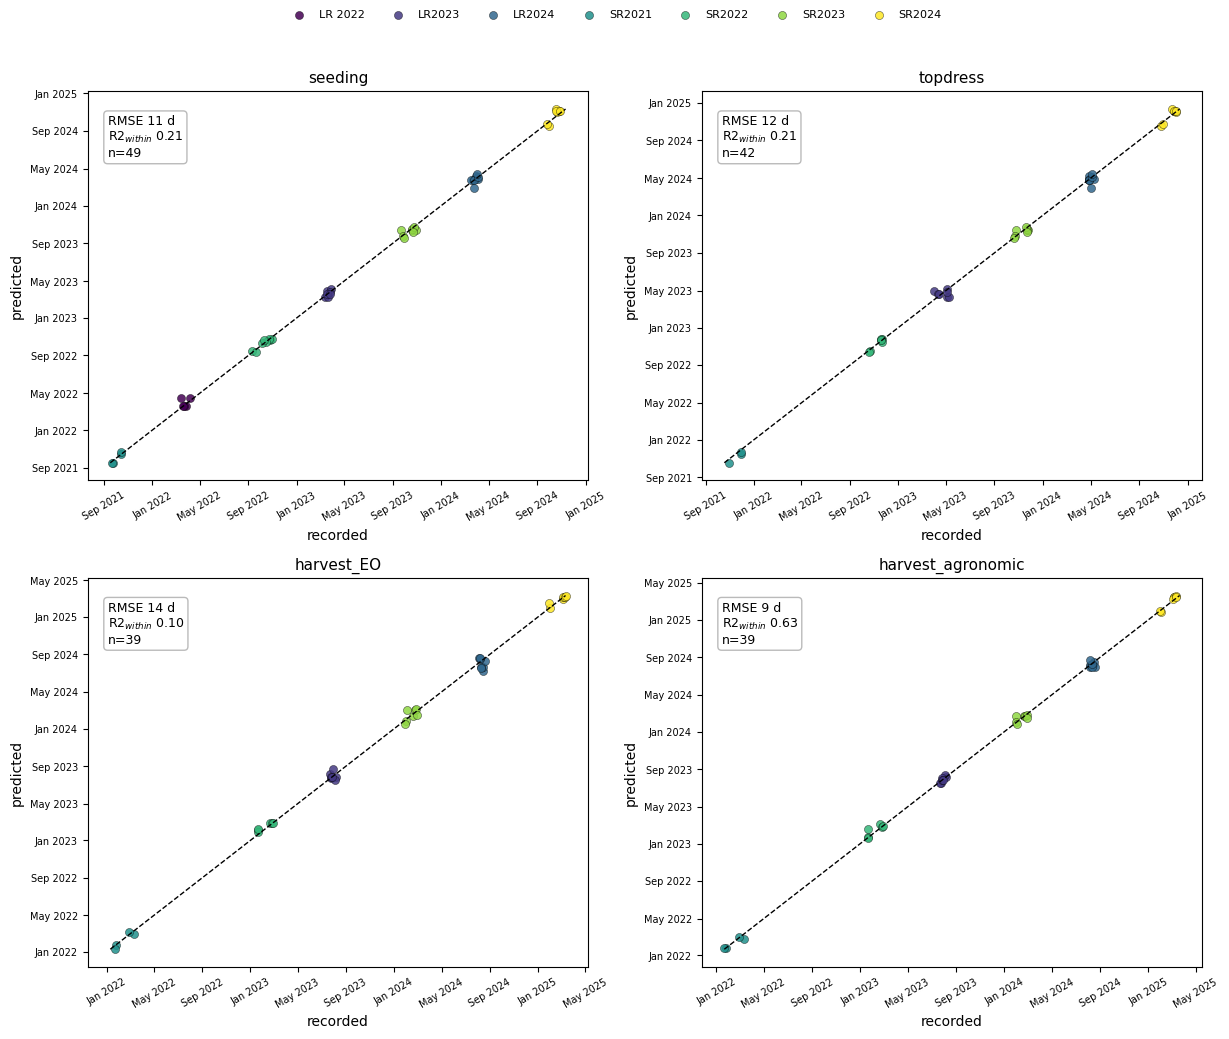

Saved fig_predicted_vs_recorded.png


In [40]:
import matplotlib.dates as mdates
_stages_plot = [(n, p, o) for n, p, o in _STAGES_M if p in cal.columns and o in cal.columns]
_ncol = 2; _nrow = int(np.ceil(len(_stages_plot) / _ncol))
fig, axes = plt.subplots(_nrow, _ncol, figsize=(6.2 * _ncol, 5.2 * _nrow), squeeze=False)
axes = np.ravel(axes)
_seasons = sorted(cal["season"].astype(str).unique())
_cmap = plt.cm.viridis(np.linspace(0, 1, len(_seasons)))
_scol = dict(zip(_seasons, _cmap))
for ax, (nm, p, o) in zip(axes, _stages_plot):
    pr = pd.to_datetime(cal[p], errors="coerce"); ob = pd.to_datetime(cal[o], errors="coerce")
    m = pr.notna() & ob.notna()
    if m.sum() < 3:
        ax.text(0.5, 0.5, f"{nm}: insufficient data", ha="center", va="center", transform=ax.transAxes)
        ax.axis("off"); continue
    for s in _seasons:
        ms = m & (cal["season"].astype(str) == s)
        if ms.any():
            ax.scatter(ob[ms], pr[ms], s=34, color=_scol[s], edgecolor="k", lw=0.3, label=s, alpha=0.85)
    lo = min(ob[m].min(), pr[m].min()); hi = max(ob[m].max(), pr[m].max())
    ax.plot([lo, hi], [lo, hi], "k--", lw=1)
    met = stage_metrics(pr, ob, cal["season"])
    ax.text(0.04, 0.94, f"RMSE {met['RMSE_d']:.0f} d\nR2$_{{within}}$ {met['R2_within']:.2f}\nn={met['n']}",
            transform=ax.transAxes, va="top", fontsize=9,
            bbox=dict(boxstyle="round", fc="white", ec="0.7", alpha=0.9))
    ax.set_title(nm, fontsize=11); ax.set_xlabel("recorded"); ax.set_ylabel("predicted")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y")); ax.tick_params(axis="x", rotation=30, labelsize=7)
    ax.yaxis.set_major_formatter(mdates.DateFormatter("%b %Y")); ax.tick_params(axis="y", labelsize=7)
for ax in axes[len(_stages_plot):]:
    ax.axis("off")
_h, _l = axes[0].get_legend_handles_labels()
fig.legend(_h, _l, loc="upper center", ncol=len(_seasons), fontsize=8, frameon=False)
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig(f"{OUT_DIR}/fig_predicted_vs_recorded.png", dpi=200); plt.show()
print("Saved fig_predicted_vs_recorded.png")

In [41]:
def je_phenology(dates, ndvi, ws, we, p=0.2):
    """Jonsson & Eklundh (2004) SOS/EOS on NDVI; the anchoring used by WorldCereal (Franch 2022)."""
    grid, x, obs, n = _resample_smooth(dates, ndvi, ws, we, SAVGOL_WIN, 2, MIN_S2_OBS)
    if grid is None:
        return {}
    g, xo = _obs_slice(grid, x, obs)
    if g is None:
        return {}
    pk = int(np.argmax(xo))
    if pk == 0 or pk == len(xo) - 1:
        return {}
    m_prev = float(np.nanmin(xo[:pk + 1])); m_post = float(np.nanmin(xo[pk:])); peak = float(xo[pk])
    if peak - m_prev <= 0:
        return {}
    up = np.where(xo[:pk + 1] >= m_prev + (peak - m_prev) * p)[0]
    dn = np.where(xo[pk:] <= m_post + (peak - m_post) * p)[0]
    return {"je_sos": g[up[0]] if len(up) else pd.NaT,
            "je_eos": g[pk + dn[0]] if len(dn) else pd.NaT}

if "NDVI" in s2_df.columns:
    _rows = []
    for _, r in fs.iterrows():
        w = windows.get(str(r.season))
        g2 = s2_df[s2_df.fs_id == r.fs_id]
        j = je_phenology(g2["date"], g2["NDVI"], *w, 0.2) if (w and len(g2)) else {}
        _rows.append(dict(fs_id=r.fs_id, je_sos=j.get("je_sos"), je_eos=j.get("je_eos")))
    _je = pd.DataFrame(_rows)
    _je["je_sos"] = pd.to_datetime(_je["je_sos"])
    cmp = cal[["fs_id", "_plant", "start_consensus"]].merge(_je, on="fs_id", how="left")
    cmp["start_consensus"] = pd.to_datetime(cmp["start_consensus"]); cmp["_plant"] = pd.to_datetime(cmp["_plant"])

    def _loo_seed(df, sos_col):
        d = df.dropna(subset=[sos_col, "_plant"]).copy()
        lag = (d[sos_col] - d["_plant"]).dt.days
        lv = lag[(lag >= 0) & (lag <= 60)]
        errs = []
        for i in lv.index:
            o = lv.drop(i)
            if len(o) >= 3:
                errs.append(((d.loc[i, sos_col] - pd.Timedelta(days=float(o.median()))) - d.loc[i, "_plant"]).days)
        e = np.array(errs, dtype=float)
        return dict(n=len(d), lag_median_d=round(float(lag.median()), 1) if len(lag) else np.nan,
                    lag_IQR_width_d=round(float(lag.quantile(.75) - lag.quantile(.25)), 1) if len(lag) else np.nan,
                    seeding_LOO_medabs_d=round(float(np.median(np.abs(e))), 1) if len(e) else np.nan,
                    n_calib=len(e))
    comparator = pd.DataFrame([
        {"detector": "this study (GCVI, trough, confirmed rise)", **_loo_seed(cmp, "start_consensus")},
        {"detector": "Jonsson-Eklundh (NDVI, p=0.2)",             **_loo_seed(cmp, "je_sos")}])
    comparator.to_csv(f"{OUT_DIR}/table_comparator_jonsson_eklundh.csv", index=False)
    print("Start-of-season detector comparison (sowing lag and leave-one-out seeding error):")
    print(comparator.to_string(index=False))
    _off = (cmp["start_consensus"] - cmp["je_sos"]).dt.days.dropna()
    if len(_off):
        print(f"\nOur SOS vs Jonsson-Eklundh SOS: median {_off.median():+.0f} d "
              f"(NDVI crosses earlier than GCVI). The two are the same method family; on these")
        print("sub-hectare fields the GCVI formulation gives a more repeatable sowing lag (narrower")
        print("IQR), which is why it is used as the anchor here.")
else:
    print("NDVI not present in s2_df; comparator skipped.")

Start-of-season detector comparison (sowing lag and leave-one-out seeding error):
                                 detector  n  lag_median_d  lag_IQR_width_d  seeding_LOO_medabs_d  n_calib
this study (GCVI, trough, confirmed rise) 49          29.0             14.0                   7.0       49
            Jonsson-Eklundh (NDVI, p=0.2) 49          15.0             26.0                   9.0       37

Our SOS vs Jonsson-Eklundh SOS: median +15 d (NDVI crosses earlier than GCVI). The two are the same method family; on these
sub-hectare fields the GCVI formulation gives a more repeatable sowing lag (narrower
IQR), which is why it is used as the anchor here.


In [42]:
# ===================== Section 16: reviewer-response analyses =====================
_EP = pd.Timestamp("2019-01-01")
cal["season"] = cal["season"].astype(str)

# ---- 16a. Skill vs a leave-one-out season-climatology baseline ----
def _season_clim_mae(obs, season):
    d = pd.DataFrame({"o": obs.values, "s": season.values}).dropna()
    errs = []
    for i in d.index:
        others = d[(d["s"] == d.loc[i, "s"]) & (d.index != i)]["o"]
        if len(others) >= 2:
            med = _EP + pd.Timedelta(days=float(((others - _EP).dt.days).median()))
            errs.append(abs((med - d.loc[i, "o"]).days))
    return (np.mean(errs), len(errs)) if errs else (np.nan, 0)

_STAGES_S = [("seeding", "seed_consensus", "_plant"),
             ("topdress", "topdress_pred", "_topdress"),
             ("harvest_EO", "harvest_consensus", "_harvest"),
             ("harvest_agronomic", "harvest_agronomic", "_harvest")]
_rows = []
for nm, pred, obs in _STAGES_S:
    if pred not in cal.columns or obs not in cal.columns:
        continue
    p = pd.to_datetime(cal[pred], errors="coerce"); o = pd.to_datetime(cal[obs], errors="coerce")
    m = p.notna() & o.notna()
    if m.sum() < 3:
        continue
    method_mae = float((p[m] - o[m]).dt.days.abs().mean())
    clim_mae, _ = _season_clim_mae(o[m], cal.loc[m, "season"])
    skill = 100 * (1 - method_mae / clim_mae) if clim_mae and clim_mae > 0 else np.nan
    _rows.append(dict(stage=nm, n=int(m.sum()), method_MAE_d=round(method_mae, 1),
                      season_climatology_MAE_d=round(clim_mae, 1),
                      skill_pct=round(skill, 0) if not np.isnan(skill) else np.nan))
baseline_skill = pd.DataFrame(_rows)
baseline_skill.to_csv(f"{OUT_DIR}/table_baseline_skill.csv", index=False)
print("16a. Skill vs season-climatology baseline (predict each plot as its season median):")
print(baseline_skill.to_string(index=False))
print("    positive skill = EO beats 'everyone in the season on one date'; it resolves plot timing.\n")

# ---- 16b. Leave-one-out vs leave-one-FARMER-out ----
def _lag_cv(anchor, target, lo, hi, sign):
    d = cal.dropna(subset=[anchor, target]).copy()
    d[anchor] = pd.to_datetime(d[anchor]); d[target] = pd.to_datetime(d[target])
    d["lag"] = (d[anchor] - d[target]).dt.days if sign < 0 else (d[target] - d[anchor]).dt.days
    d = d[d["lag"].between(lo, hi)]
    res = {}
    for mode in ["LOO", "LOFO"]:
        e = []
        for i in d.index:
            o = d.drop(i) if mode == "LOO" else d[d["farmer"] != d.loc[i, "farmer"]]
            if len(o) < 3:
                continue
            ml = float(o["lag"].median())
            pred = d.loc[i, anchor] - pd.Timedelta(days=ml) if sign < 0 else d.loc[i, anchor] + pd.Timedelta(days=ml)
            e.append(abs((pred - d.loc[i, target]).days))
        res[mode] = (np.median(e), np.mean(e), len(e)) if e else (np.nan, np.nan, 0)
    return res

_CV = [("seeding", "start_consensus", "_plant", 0, 60, -1),
       ("topdress", "start_consensus", "_topdress", -30, 90, 1),
       ("harvest_EO", "harvest_raw", "_harvest", -30, 60, 1)]
_rows = []
for nm, a, t, lo, hi, sg in _CV:
    if a not in cal.columns or t not in cal.columns:
        continue
    r = _lag_cv(a, t, lo, hi, sg)
    _rows.append(dict(stage=nm,
                      LOO_medabs_d=round(r["LOO"][0], 1), LOO_MAE_d=round(r["LOO"][1], 1),
                      LOFO_medabs_d=round(r["LOFO"][0], 1), LOFO_MAE_d=round(r["LOFO"][1], 1),
                      delta_medabs_d=round(r["LOFO"][0] - r["LOO"][0], 1), n=r["LOO"][2]))
transfer = pd.DataFrame(_rows)
transfer.to_csv(f"{OUT_DIR}/table_loo_vs_lofo.csv", index=False)
print("16b. Leave-one-out vs leave-one-FARMER-out (transfer to an unseen farmer):")
print(transfer.to_string(index=False))
print("    a small delta means the lags are population constants: no pseudo-replication inflation.\n")

# ---- 16c. Empirical coverage of the seeding prediction bracket ----
if {"seed_early", "seed_late", "_plant"} <= set(cal.columns):
    for c in ["seed_early", "seed_late", "_plant", "start_consensus"]:
        cal[c] = pd.to_datetime(cal[c], errors="coerce")
    m = cal["seed_early"].notna() & cal["seed_late"].notna() & cal["_plant"].notna()
    _blo = cal.loc[m, ["seed_early", "seed_late"]].min(axis=1)
    _bhi = cal.loc[m, ["seed_early", "seed_late"]].max(axis=1)
    inside = (cal.loc[m, "_plant"] >= _blo) & (cal.loc[m, "_plant"] <= _bhi)
    print("16c. Seeding prediction interval:")
    print(f"    IQR bracket [seed_early, seed_late] (nominal ~50%): recorded sowing inside "
          f"{int(inside.sum())}/{int(m.sum())} = {100*inside.mean():.0f}%")
    d = cal.dropna(subset=["start_consensus", "_plant"]).copy()
    d["lag"] = (d["start_consensus"] - d["_plant"]).dt.days
    lv = d["lag"][d["lag"].between(0, 60)]
    if len(lv) >= 8:
        q_lo, q_hi = float(lv.quantile(.05)), float(lv.quantile(.95))
        p_lo = cal["start_consensus"] - pd.to_timedelta(q_hi, unit="D")
        p_hi = cal["start_consensus"] - pd.to_timedelta(q_lo, unit="D")
        m2 = p_lo.notna() & p_hi.notna() & cal["_plant"].notna()
        ins90 = (cal.loc[m2, "_plant"] >= p_lo[m2]) & (cal.loc[m2, "_plant"] <= p_hi[m2])
        print(f"    wider interval from 5th-95th lag percentiles ([-{q_hi:.0f}, -{q_lo:.0f}] d), "
              f"nominal ~90%: covers {100*ins90.mean():.0f}%")
    print("    the method returns a date AND a defensible range, which is the interval reviewers expect.")
else:
    print("16c. seed_early/seed_late not present; run Section 9 for the bracket.")

# ---- paper-ready metric set (R2_within only; R2_across omitted by design) ----
if "stage_metrics_tbl" in dir():
    paper_metrics = stage_metrics_tbl.drop(columns=[c for c in ["R2_across"] if c in stage_metrics_tbl.columns]).copy()
    paper_metrics = paper_metrics.merge(baseline_skill[["stage", "skill_pct"]], on="stage", how="left")
    paper_metrics.to_csv(f"{OUT_DIR}/table_paper_metrics.csv", index=False)
    print("\nPaper-ready per-stage table (R2_within only; climatology skill appended):")
    print(paper_metrics.to_string(index=False))

16a. Skill vs season-climatology baseline (predict each plot as its season median):
            stage  n  method_MAE_d  season_climatology_MAE_d  skill_pct
          seeding 49           8.1                      10.5       23.0
         topdress 42           9.0                      11.4       21.0
       harvest_EO 39          10.7                      15.6       31.0
harvest_agronomic 39           6.3                      15.6       59.0
    positive skill = EO beats 'everyone in the season on one date'; it resolves plot timing.

16b. Leave-one-out vs leave-one-FARMER-out (transfer to an unseen farmer):
     stage  LOO_medabs_d  LOO_MAE_d  LOFO_medabs_d  LOFO_MAE_d  delta_medabs_d  n
   seeding           7.0        8.6            7.0         8.4             0.0 49
  topdress           7.5        9.0            8.0         9.1             0.5 42
harvest_EO           9.0       11.2           10.0        11.2             1.0 39
    a small delta means the lags are population constants: 

In [ ]:
import geopandas as gpd

# 1. Load Kenyan administrative boundaries shapefile
kenya_boundaries_path = "/content/gadm41_KEN_1.shp" # Changed from KEN_2.shp to KEN_1.shp
try:
    kenya_counties = gpd.read_file(kenya_boundaries_path)
    # Ensure CRS is WGS84, which is common for geographic coordinates
    if kenya_counties.crs != 'EPSG:4326':
        kenya_counties = kenya_counties.to_crs('EPSG:4326')
    print(f"Loaded {len(kenya_counties)} Kenyan administrative boundaries.")
    # Display first few rows to confirm column names, especially for county
    print("Kenya counties GeoDataFrame head:")
    display(kenya_counties.head())
except FileNotFoundError:
    print(f"Error: Kenyan administrative boundaries shapefile not found at {kenya_boundaries_path}.")
    kenya_counties = None

if kenya_counties is not None and not fs.empty:
    # 2. Create a GeoDataFrame from the farmers' coordinates from the already filtered `fs` DataFrame.
    # These are the same coordinates used for Sentinel-2 data extraction.
    farmers_gdf = gpd.GeoDataFrame(
        fs.copy(),
        geometry=gpd.points_from_xy(fs['lon'], fs['lat']),
        crs="EPSG:4326"
    )
    print(f"Created GeoDataFrame for {len(farmers_gdf)} farmers.")

    # 3. Perform a spatial join between farmer points and county boundaries.
    # 'left' join keeps all farmers, assigning NaN to 'NAME_1' if no county is found.
    # 'NAME_1' is typically the column containing county names for GADM level 1.
    farmers_with_counties = gpd.sjoin(farmers_gdf, kenya_counties[['NAME_1', 'geometry']], how="left", predicate="within") # Changed 'NAME_2' to 'NAME_1'

    # Rename the county column for consistency with the requested 'County' column.
    farmers_with_counties.rename(columns={'NAME_1': 'County_Geospatial'}, inplace=True)
    print(f"Spatially joined {len(farmers_with_counties)} farmers with counties.")
    display(farmers_with_counties[['fs_id', 'lat', 'lon', 'County_Geospatial']].head())

    # 4. Construct the final table
    # Calculate 'Number Seasons' from the already filtered `fs` DataFrame.
    seasons_per_farmer = fs.groupby('farmer')['season'].nunique().reset_index()
    seasons_per_farmer.rename(columns={'season': 'Number Seasons'}, inplace=True)

    # Get Region information. This comes from the original `df` (unfiltered) and is mapped to each farmer_field.
    # First, create a unique farmer_field identifier in the original df for merging
    df_region_mapping = df.groupby([COL['farmer'], COL['field']]).agg({
        'region': 'first',
    }).reset_index()

    df_region_mapping['Farmer_field'] = (
        df_region_mapping[COL['farmer']].astype(str).str.strip() + '__' +
        df_region_mapping[COL['field']].astype(str).str.strip()
    )

    # Prepare data for final table from the spatially joined GeoDataFrame.
    # `farmers_with_counties` already contains only the farmers filtered by `MIN_SEASONS_PER_FARMER`.
    temp_table = farmers_with_counties[[
        'fs_id', 'farmer', 'field', 'lat', 'lon', 'County_Geospatial'
    ]].copy()

    # Create 'Farmer_field' column for merging with region info.
    temp_table['Farmer_field'] = (
        temp_table['farmer'].astype(str).str.strip() + '__' +
        temp_table['field'].astype(str).str.strip()
    )

    # Merge 'Number Seasons'.
    temp_table = temp_table.merge(seasons_per_farmer, on='farmer', how='left')

    # Merge 'Region'.
    # Use the 'Farmer_field' column for merging to ensure correct region assignment
    temp_table = temp_table.merge(
        df_region_mapping[['Farmer_field', 'region']],
        on='Farmer_field',
        how='left'
    )

    # Select and rename final columns as requested by the user.
    final_table = temp_table[[
        'Farmer_field', 'region', 'County_Geospatial', 'lat', 'lon', 'Number Seasons'
    ]].rename(columns={
        'region': 'Region',
        'County_Geospatial': 'County',
        'lat': 'Latitude',
        'lon': 'Longitude'
    })

    print(f"Final table created with {len(final_table)} rows.")
    display(final_table.head())
    print(f"Unique Farmer_fields in final_table: {final_table['Farmer_field'].nunique()}")
    print(f"Unique farmers in final_table: {final_table['Farmer_field'].apply(lambda x: x.split('__')[0]).nunique()}")

    # Check for NaN in 'County' column and report.
    nan_counties = final_table['County'].isnull().sum()
    if nan_counties > 0:
        print(f"Warning: {nan_counties} entries have NaN in the 'County' column after spatial join. This might indicate points outside the provided county boundaries or issues with the boundaries file.")

    # Save the final table to a CSV file
    final_table.to_csv(f"{OUT_DIR}/final_farmers_table.csv", index=False) # Added line to save to CSV
    print(f"Final table saved to {OUT_DIR}/final_farmers_table.csv")
else:
    print("Skipping final_table creation due to missing Kenya boundaries or empty fs DataFrame.")

In [45]:
import os
import numpy as np
import pandas as pd

# ------------------------------------------------------------------ settings
B = 2000            # bootstrap resamples
SEED = 42
ALPHA = 0.05
DATA_DIR = "/content/eo_ofe_outputs"      # folder holding the two CSV files
OUT_DIR = "bootstrap_outputs"

try:                # Colab: offer upload if the files are not already there
    from google.colab import files  # noqa: F401
    need = [f for f in ["table_plot_error_by_stage.csv", "table_calendar_check.csv"]
            if not os.path.exists(os.path.join(DATA_DIR, f))]
    if need:
        print("Upload:", need)
        files.upload()
except ImportError:
    pass

os.makedirs(OUT_DIR, exist_ok=True)
rng = np.random.default_rng(SEED)

In [46]:
# ------------------------------------------------------------------ load
pe = pd.read_csv(os.path.join(DATA_DIR, "table_plot_error_by_stage.csv"),
                 parse_dates=["seeding_rec", "seeding_pred", "topdress_rec", "harvest_rec"])
cc = pd.read_csv(os.path.join(DATA_DIR, "table_calendar_check.csv"),
                 parse_dates=["start_consensus", "harvest_raw"])
d = pe.merge(cc[["fs_id", "start_consensus", "harvest_raw"]], on="fs_id", how="left")
d["season"] = d["season"].astype(str).str.replace(" ", "", regex=False)


In [50]:
def baseline_abs_error(rec, season):
    """|recorded - median recorded date of the OTHER field-seasons in the same season|."""
    o = rec.map(pd.Timestamp.toordinal).astype(float)
    out = pd.Series(np.nan, index=rec.index)
    for i in rec.index:
        others = o[(season == season[i]) & (o.index != i)]
        if len(others):
            out[i] = abs(o[i] - others.median())
    return out

# Map each stage to: (recorded_col, loo_error_col, anchor_or_pred_col, sign)
STAGES_DICT = {
    "seeding": ("seeding_rec", "seeding_loo_err_d", d["start_consensus"], -1),
    "topdress": ("topdress_rec", "topdress_loo_err_d", d["start_consensus"], 1),
    "harvest": ("harvest_rec", "harvest_loo_err_d", d["harvest_raw"], 1)
}

rows = []
for stage, (rec_col, loo_col, x, sign) in STAGES_DICT.items():
    m = d[rec_col].notna() & d[loo_col].notna() & x.notna()
    sub = d[m]
    xs, farm = x[m], sub["farmer"]
    lofo = pd.Series({i: np.floor(sign * (xs[i] - xs[farm != farm[i]].median()).days) for i in xs.index})
    base = baseline_abs_error(sub[rec_col], sub["season"])
    rows.append(pd.DataFrame({"stage": stage, "fs_id": sub["fs_id"], "farmer": farm,
                              "season": sub["season"], "loo_err": sub[loo_col],
                              "lofo_err": lofo, "base_abs": base}))
E = pd.concat(rows, ignore_index=True)
E.to_csv(os.path.join(OUT_DIR, "per_fieldseason_errors.csv"), index=False)

In [51]:

# ------------------------------------------------------------------ metrics
def metrics(g):
    a, l = g["loo_err"].abs(), g["lofo_err"].abs()
    mae, base = a.mean(), g["base_abs"].mean()
    return {"n": len(g),
            "median_abs_d": a.median(), "MAE_d": mae,
            "within10_pct": 100 * (a <= 10).mean(),
            "baseline_MAE_d": base,
            "skill_pct": 100 * (1 - mae / base) if base > 0 else np.nan,
            "LOFO_median_abs_d": l.median(), "LOFO_MAE_d": l.mean(),
            "dLOFO_median_abs_d": l.median() - a.median(), "dLOFO_MAE_d": l.mean() - a.mean()}


def block_boot(df, B, rng):
    """Resample farmers with replacement; keep all field-seasons of each drawn farmer."""
    farmers = df["farmer"].unique()
    groups = {f: df[df["farmer"] == f] for f in farmers}
    out = []
    for _ in range(B):
        draw = rng.choice(farmers, size=len(farmers), replace=True)
        out.append(metrics(pd.concat([groups[f] for f in draw], ignore_index=True)))
    return pd.DataFrame(out)


def summarise(point, boot, label_cols):
    rec = dict(label_cols)
    for k, v in point.items():
        rec[k] = v
        if k != "n":
            lo, hi = np.nanpercentile(boot[k], [100 * ALPHA / 2, 100 * (1 - ALPHA / 2)])
            rec[k + "_lo"], rec[k + "_hi"] = lo, hi
    if "skill_pct" in boot:
        rec["P(skill<=0)"] = float((boot["skill_pct"] <= 0).mean())
    return rec


# pooled (Tables 2, 3, 4 and Abstract)
pooled = []
for stage, g in E.groupby("stage", sort=False):
    pooled.append(summarise(metrics(g), block_boot(g, B, rng), {"stage": stage}))
pooled = pd.DataFrame(pooled)
pooled.to_csv(os.path.join(OUT_DIR, "bootstrap_pooled.csv"), index=False)

# per season (Table S1): farmers resampled within each season
per_season = []
for (stage, season), g in E.groupby(["stage", "season"], sort=False):
    if len(g) < 3:
        continue
    per_season.append(summarise(metrics(g), block_boot(g, B, rng), {"stage": stage, "season": season}))
per_season = pd.DataFrame(per_season)
per_season.to_csv(os.path.join(OUT_DIR, "bootstrap_per_season.csv"), index=False)


# ------------------------------------------------------------------ readable print-out
def fmt(r, k, dp=1):
    return f"{r[k]:.{dp}f} [{r[k + '_lo']:.{dp}f}, {r[k + '_hi']:.{dp}f}]"


print(f"\nFarmer-block bootstrap, B = {B}, seed = {SEED}, 95% percentile intervals\n")
for _, r in pooled.iterrows():
    print(f"{r['stage']:18s} n={int(r['n'])}  median|e| {fmt(r, 'median_abs_d')}  MAE {fmt(r, 'MAE_d')}  "
          f"within10 {fmt(r, 'within10_pct', 0)}%  skill {fmt(r, 'skill_pct', 0)}%  P(skill<=0)={r['P(skill<=0)']:.3f}")
    print(f"{'':18s} LOFO median|e| {fmt(r, 'LOFO_median_abs_d')}  LOFO MAE {fmt(r, 'LOFO_MAE_d')}  "
          f"dMAE {fmt(r, 'dLOFO_MAE_d')}")
print("\nPer-season skill (%):")
for _, r in per_season.iterrows():
    print(f"  {r['stage']:18s} {r['season']}  n={int(r['n'])}  skill {fmt(r, 'skill_pct', 0)}  "
          f"MAE {fmt(r, 'MAE_d')}  P(skill<=0)={r['P(skill<=0)']:.2f}")
print(f"\nCSV files written to ./{OUT_DIR}/")



Farmer-block bootstrap, B = 2000, seed = 42, 95% percentile intervals

seeding            n=49  median|e| 7.0 [5.0, 10.0]  MAE 8.6 [6.4, 10.7]  within10 65 [50, 80]%  skill 18 [-22, 48]%  P(skill<=0)=0.207
                   LOFO median|e| 276.0 [249.0, 355.0]  LOFO MAE 310.7 [274.5, 344.1]  dMAE 302.2 [266.4, 335.5]
topdress           n=42  median|e| 7.5 [5.0, 9.0]  MAE 9.0 [6.8, 11.8]  within10 71 [57, 84]%  skill 21 [-55, 55]%  P(skill<=0)=0.239
                   LOFO median|e| 208.0 [198.0, 218.0]  LOFO MAE 257.2 [219.5, 291.8]  dMAE 248.2 [209.6, 283.3]
harvest            n=39  median|e| 9.0 [7.0, 14.5]  MAE 11.2 [8.7, 14.4]  within10 54 [36, 71]%  skill 28 [-14, 51]%  P(skill<=0)=0.073
                   LOFO median|e| 203.0 [188.0, 208.0]  LOFO MAE 274.4 [234.9, 302.7]  dMAE 263.2 [221.1, 293.1]

Per-season skill (%):
  seeding            LR2023  n=7  skill 0 [-85, 48]  MAE 6.9 [4.1, 9.7]  P(skill<=0)=0.51
  seeding            LR2024  n=9  skill -38 [-204, 43]  MAE 7.7 [3.4, 1

In [52]:
import pandas as pd
import numpy as np

# Load the generated bootstrap pooled metrics
pooled_path = "./bootstrap_outputs/bootstrap_pooled.csv"
if os.path.exists(pooled_path):
    pooled_df = pd.read_csv(pooled_path)

    print("=== BOOTSTRAP EVALUATION SUMMARY ===\n")
    for _, row in pooled_df.iterrows():
        stage = row["stage"].upper()
        print(f"--- {stage} --- (n = {int(row['n'])})")
        print(f"  * Median Absolute Error: {row['median_abs_d']:.1f} days (95% CI: {row['median_abs_d_lo']:.1f} to {row['median_abs_d_hi']:.1f} days)")
        print(f"  * Mean Absolute Error (MAE): {row['MAE_d']:.1f} days (95% CI: {row['MAE_d_lo']:.1f} to {row['MAE_d_hi']:.1f} days)")
        print(f"  * Within-10-Day Accuracy: {row['within10_pct']:.1f}% (95% CI: {row['within10_pct_lo']:.1f}% to {row['within10_pct_hi']:.1f}%)")
        print(f"  * Skill over Climatology: {row['skill_pct']:.1f}% (95% CI: {row['skill_pct_lo']:.1f}% to {row['skill_pct_hi']:.1f}%)")
        print(f"  * Probability of No/Negative Skill: P(skill <= 0) = {row['P(skill<=0)']:.3f}")
        print(f"  * LOFO MAE: {row['LOFO_MAE_d']:.1f} days (95% CI: {row['LOFO_MAE_d_lo']:.1f} to {row['LOFO_MAE_d_hi']:.1f} days)\n")
else:
    print("Bootstrap pooled results file not found. Please ensure the bootstrap step completed successfully.")

=== BOOTSTRAP EVALUATION SUMMARY ===

--- SEEDING --- (n = 49)
  * Median Absolute Error: 7.0 days (95% CI: 5.0 to 10.0 days)
  * Mean Absolute Error (MAE): 8.6 days (95% CI: 6.4 to 10.7 days)
  * Within-10-Day Accuracy: 65.3% (95% CI: 50.0% to 80.4%)
  * Skill over Climatology: 17.9% (95% CI: -22.2% to 47.6%)
  * Probability of No/Negative Skill: P(skill <= 0) = 0.207
  * LOFO MAE: 310.7 days (95% CI: 274.5 to 344.1 days)

--- TOPDRESS --- (n = 42)
  * Median Absolute Error: 7.5 days (95% CI: 5.0 to 9.0 days)
  * Mean Absolute Error (MAE): 9.0 days (95% CI: 6.8 to 11.8 days)
  * Within-10-Day Accuracy: 71.4% (95% CI: 57.1% to 83.7%)
  * Skill over Climatology: 20.9% (95% CI: -55.1% to 55.2%)
  * Probability of No/Negative Skill: P(skill <= 0) = 0.239
  * LOFO MAE: 257.2 days (95% CI: 219.5 to 291.8 days)

--- HARVEST --- (n = 39)
  * Median Absolute Error: 9.0 days (95% CI: 7.0 to 14.5 days)
  * Mean Absolute Error (MAE): 11.2 days (95% CI: 8.7 to 14.4 days)
  * Within-10-Day Accuracy